# Tugas Terstruktur dan Milestone Proyek UAS — Pertemuan 11 
## Evaluasi Kalibrasi Probabilitas dan Pemilihan Ambang Keputusan Berbasis Biaya pada Klasifikasi Status *Dropout* Mahasiswa Menggunakan Informasi hingga Akhir Semester Pertama: Studi pada Dataset UCI #697

---

### Identitas Mahasiswa dan Informasi Berkas Revisi
| Komponen | Keterangan |
| :--- | :--- |
| **Nama Mahasiswa** | Fadli Hifziansyah |
| **NIM** | `241730042` |
| **Kelas** | `5 INF B` |
| **Mata Kuliah** | Pembelajaran Mesin (*Machine Learning*) — Pertemuan 11 |
| **Dosen Pengampu** | Bapak Ahmad Tabrani |
| **Sumber Dataset Empiris** | *Predict Students' Dropout and Academic Success* — UCI Machine Learning Repository ID #697 (DOI Resmi Dataset: `10.24432/C5MC89`; Artikel Deskripsi Dataset: Realinho et al., 2022, DOI: `10.3390/data7110146`; Lisensi `CC BY 4.0`; berkas lokal `dataset-asli.csv`) |
| **Berkas Notebook Revisi** | `241730042_Fadli_Hifziansyah_P11_TugasML_REVISI.ipynb` *(berkas asli dipertahankan utuh tanpa ditimpa)* |

---

### Peta Kesesuaian terhadap Instruksi Tugas Dosen (11 Langkah, 5 Latihan Analitis, & 8 Luaran)
| Instruksi Tugas Dosen | Lokasi Pengerjaan pada Notebook Revisi |
| :--- | :--- |
| **Langkah 1:** Konteks kasus, unit analisis, kelas positif, dan keputusan yang dibantu | **Bagian 1** & **Bagian 2.5** |
| **Langkah 2:** Hitung *confusion matrix* & metrik pada *threshold* `0,5` lalu bandingkan dengan `0,3` dan `0,7` (data validasi) | **Bagian 5.2** |
| **Langkah 3:** Sajikan perbandingan *Precision*, *Recall*, *Specificity*, dan *F1-Score* | **Bagian 5.2** & **Bagian 6.3–6.4** |
| **Langkah 4 & 5:** Hitung `ROC-AUC` & `PR-AUC` (`Average Precision` sebagai metrik PR utama vs. *Trapezoidal PR-AUC*), plot *ROC* & *PR Curve* | **Bagian 5.1** & **Bagian 5.3** |
| **Langkah 6:** Periksa kualitas kalibrasi probabilitas model (*Brier Score*, `ECE`, per-*bin*, *Reliability Diagram*) | **Bagian 5.1** & **Bagian 5.3** |
| **Langkah 7:** Susun matriks biaya *False Positive* dan *False Negative* | **Bagian 6.1** & **Bagian 6.3** |
| **Langkah 8:** Pilih *threshold* operasional (`0,3483` eksak sebagai minimum biaya skenario kapasitas simulasi 35%; `0,34` & `0,35` sebagai sensitivitas grid `0,01`) | **Bagian 6.2–6.5** & Evaluasi Akhir Satu Kali *Test Set* di **Bagian 7.2** |
| **Langkah 9:** Analisis minimal tiga kesalahan prediksi yang penting | **Bagian 7.1** (4 kasus nyata di *Validation Set*: Fakta, Interpretasi, Hipotesis) |
| **Langkah 10:** Proposal singkat artikel UAS (pertanyaan riset, dataset, *baseline*, model, metrik, rencana eksperimen) | **Bagian 8.1** & dokumen mandiri `Proposal_Penelitian_UAS_P11_Fadli_Hifziansyah.docx` |
| **Langkah 11:** Calon jurnal SINTA 4 & pemeriksaan jujur ketersediaan bukti verifikasi | **Bagian 8.2** & folder `bukti_sinta/` |
| **Latihan Analitis 1–5:** Prioritas *Recall*, hitung *Precision* (`TP=40, FP=10`), pentingnya *Specificity*, *baseline* `AP`/kurva PR, Diskriminasi vs. Kalibrasi | **Bagian 9.1** |

---

### Langkah 1 — Konteks Kasus, Unit Analisis, Kelas Positif, dan Keputusan yang Dibantu
* **Konteks Masalah dan Keputusan yang Dibantu:** Putus studi (*dropout*) pada pendidikan tinggi berdampak pada hilangnya capaian akademik mahasiswa serta inefisiensi sumber daya pembelajaran institusi. Model klasifikasi pada penelitian ini dirancang sebagai pendukung keputusan untuk mengidentifikasi mahasiswa dengan probabilitas risiko *dropout* tinggi menggunakan informasi yang tersedia **hingga akhir Semester Pertama**, guna memprioritaskan alokasi tindak lanjut pendampingan akademik sebelum perkuliahan Semester Kedua berjalan *(catatan: studi ini mengevaluasi kinerja prediktif dan keputusan ambang pada data observasional, bukan menguji efektivitas kausal intervensi pencegahan dropout)*.
* **Unit Analisis:** Satu baris observasi merepresentasikan **satu individu mahasiswa program sarjana** pada institusi pendidikan tinggi asal dataset (*Instituto Politécnico de Portalegre*, Portugal).
* **Definisi Kelas Positif dan Kelas Negatif:**
  * **Kelas Positif (`1` — `Dropout`):** Mahasiswa dengan status tercatat `Dropout` pada *endpoint* pengamatan dataset (`1.421` dari `4.424` mahasiswa; `32,12%`).
  * **Kelas Negatif (`0` — Tidak Dilabeli `Dropout` pada *Endpoint* Pengamatan):** Gabungan mahasiswa berstatus `Graduate` (`2.209`; `49,93%`) dan `Enrolled` (`794`; `17,95%`), seluruhnya `3.003` mahasiswa (`67,88%`). Mahasiswa berlabel `Enrolled` **tidak** diartikan sebagai mahasiswa yang sudah dipastikan bertahan atau lulus karena status sesudah jendela pengamatan tidak tersedia.
* **Asimetri Konsekuensi Kesalahan Klasifikasi:**
  * **False Positive (FP):** Mahasiswa berlabel non-*dropout* pada *endpoint* pengamatan ikut ditandai positif sehingga menyerap kuota tindak lanjut konseling yang terbatas.
  * **False Negative (FN):** Mahasiswa yang benar-benar berstatus akhir `Dropout` terlewat tanpa penandaan risiko pada akhir Semester Pertama.


In [16]:
# Bagian 1.1: Konfigurasi Identitas Mahasiswa dan Parameter Studi
identitas_studi = {
    "nama": "Fadli Hifziansyah",
    "nim": "241730042",
    "kelas": "5 INF B",
    "mata_kuliah": "Machine Learning - Pertemuan 11",
    "dosen_pengampu": "Bapak Ahmad Tabrani",
    "judul_penelitian": (
        "Evaluasi Kalibrasi Probabilitas dan Pemilihan Ambang Keputusan Berbasis Biaya pada "
        "Klasifikasi Status Dropout Mahasiswa Menggunakan Informasi hingga Akhir Semester Pertama: "
        "Studi pada Dataset UCI #697"
    ),
    "doi_dataset_uci": "10.24432/C5MC89",
    "doi_artikel_deskripsi": "10.3390/data7110146",
}
for k, v in identitas_studi.items():
    print(f"{k:24s}: {v}")


nama                    : Fadli Hifziansyah
nim                     : 241730042
kelas                   : 5 INF B
mata_kuliah             : Machine Learning - Pertemuan 11
dosen_pengampu          : Bapak Ahmad Tabrani
judul_penelitian        : Evaluasi Kalibrasi Probabilitas dan Pemilihan Ambang Keputusan Berbasis Biaya pada Klasifikasi Status Dropout Mahasiswa Menggunakan Informasi hingga Akhir Semester Pertama: Studi pada Dataset UCI #697
doi_dataset_uci         : 10.24432/C5MC89
doi_artikel_deskripsi   : 10.3390/data7110146


---
## BAGIAN 2 — Dataset, Perubahan Sumber Data, Audit Kelas `Enrolled`, dan Spesifikasi Fitur

### 2.1 Perubahan Sumber Dataset dan Konsistensi Eksperimen
1. **Dataset Sintetis pada Pertemuan Sebelumnya:** Pada pertemuan sebelumnya digunakan dataset sintetis hasil simulasi komputer untuk mengeksplorasi skenario variabel yang didekatkan dengan istilah administrasi perguruan tinggi di Indonesia. Data tersebut merupakan **simulasi dengan asumsi pemodelan**, bukan data empiris mahasiswa Indonesia.
2. **Dataset Empiris UCI #697 pada Pertemuan 11:** Mulai Pertemuan 11 digunakan dataset empiris publik **Predict Students' Dropout and Academic Success** dari **UCI Machine Learning Repository (ID #697)** dalam berkas lokal `dataset-asli.csv` yang berasal dari institusi pendidikan tinggi di Portugal.
3. **Pemisahan Penuh Hasil:** Seluruh proses *preprocessing*, pemodelan, kalibrasi, pencarian *threshold*, dan evaluasi pada Pertemuan 11 dihitung ulang sepenuhnya dari `dataset-asli.csv` tanpa menggabungkan angka maupun asumsi dari eksperimen sintetis sebelumnya. Hasil pada dataset Portugal ini juga tidak otomatis mewakili kondisi mahasiswa perguruan tinggi di Indonesia.

### 2.2 Sumber Resmi Dataset UCI #697
* **Repositori Resmi:** https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success
* **DOI Resmi Dataset:** `10.24432/C5MC89` (Realinho, Machado, Baptista, & Martins, 2021; Lisensi `CC BY 4.0`)
* **DOI Artikel Deskripsi Dataset (Terpisah):** `10.3390/data7110146` (Realinho et al., 2022, *Data*, 7(11), 146)


In [17]:
# Bagian 2.3: Import Pustaka, Pemeriksaan SHA-256 Penuh (64 Karakter), dan Pembacaan dataset-asli.csv
from pathlib import Path
import hashlib
import random
import urllib.request
import warnings

from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    auc,
    brier_score_loss,
)

# Penanganan warning spesifik (tanpa warnings.filterwarnings('ignore') global)
warnings.filterwarnings("ignore", category=FutureWarning, module=r"sklearn\..*")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["font.size"] = 9.5

LAMPIRAN_DIR = Path("lampiran_proposal")
LAMPIRAN_TAB_DIR = LAMPIRAN_DIR / "tabel"
LAMPIRAN_VIS_DIR = LAMPIRAN_DIR / "grafik_grayscale"
LAMPIRAN_TAB_DIR.mkdir(parents=True, exist_ok=True)
LAMPIRAN_VIS_DIR.mkdir(parents=True, exist_ok=True)

# Cermin repositori GitHub publik mahasiswa sebagai fallback eksekusi awan (mis. Google Colab)
GITHUB_RAW_URL = (
    "https://raw.githubusercontent.com/fadli154/mesin-learning-smt5/refs/heads/main/dataset-asli.csv"
)
# Hash SHA-256 penuh (64 heksadesimal) untuk menjaga reproduksibilitas antarsalinan kerja proyek
# (Catatan: hash ini memverifikasi konsistensi byte salinan lokal & cermin GitHub, bukan tanda tangan resmi UCI)
EXPECTED_LF_SHA256_FULL = "19737f02127e85ef29af536e46888a7721b6c530c3e1c6aedfbb09109c030a71"


def temukan_atau_unduh_dataset(
    nama_file: str = "dataset-asli.csv",
    fallback_url: str = GITHUB_RAW_URL,
) -> tuple[Path, str]:
    for p in [Path(nama_file), Path("..") / nama_file, Path("Pertemuan 11") / nama_file]:
        if p.is_file():
            return p, f"Berkas lokal ({p})"
    target_unduh = Path(nama_file)
    print(f"Berkas lokal '{nama_file}' tidak ditemukan; mengunduh dari cermin GitHub Raw...")
    req = urllib.request.Request(fallback_url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=30) as resp, open(target_unduh, "wb") as out_f:
        out_f.write(resp.read())
    return target_unduh, f"Unduhan otomatis cermin GitHub Raw ({target_unduh})"


path_dataset_aktual, sumber_aktif = temukan_atau_unduh_dataset("dataset-asli.csv")
raw_bytes = path_dataset_aktual.read_bytes()
sha256_raw_full = hashlib.sha256(raw_bytes).hexdigest()
sha256_lf_full = hashlib.sha256(raw_bytes.replace(b"\r\n", b"\n")).hexdigest()
has_utf8_bom = raw_bytes.startswith(b"\xef\xbb\xbf")

baris_header_mentah = raw_bytes.decode("utf-8-sig").splitlines()[0]
sep_terdeteksi = ";" if baris_header_mentah.count(";") > baris_header_mentah.count(",") else ","

df_mentah = pd.read_csv(path_dataset_aktual, sep=sep_terdeteksi, encoding="utf-8-sig")
kolom_ber_whitespace = [c for c in df_mentah.columns if c != c.strip()]
df_uci = df_mentah.copy()
df_uci.columns = [c.strip() for c in df_uci.columns]

assert sha256_lf_full == EXPECTED_LF_SHA256_FULL, "Full SHA-256 (LF) berbeda dari berkas acuan eksperimen!"
print(f"Nama berkas dataset          : {path_dataset_aktual.name} ({len(raw_bytes):,} byte)")
print(f"Sumber pembacaan aktif       : {sumber_aktif}")
print(f"Full SHA-256 (byte mentah)   : {sha256_raw_full}")
print(f"Full SHA-256 (LF-normalized) : {sha256_lf_full}")
print("Status verifikasi checksum   : Konsisten 64/64 karakter heksadesimal dengan salinan kerja eksperimen.")
print(f"UTF-8 BOM: {has_utf8_bom} | Delimiter: '{sep_terdeteksi}' | Kolom dirapikan .strip(): {kolom_ber_whitespace}")
print(f"Dimensi aktual DataFrame     : {df_uci.shape[0]:,} baris observasi x {df_uci.shape[1]} kolom")


Nama berkas dataset          : dataset-asli.csv (533,230 byte)
Sumber pembacaan aktif       : Berkas lokal (dataset-asli.csv)
Full SHA-256 (byte mentah)   : 3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae
Full SHA-256 (LF-normalized) : 19737f02127e85ef29af536e46888a7721b6c530c3e1c6aedfbb09109c030a71
Status verifikasi checksum   : Konsisten 64/64 karakter heksadesimal dengan salinan kerja eksperimen.
UTF-8 BOM: True | Delimiter: ';' | Kolom dirapikan .strip(): ['Daytime/evening attendance\t']
Dimensi aktual DataFrame     : 4,424 baris observasi x 37 kolom


In [18]:
# Bagian 2.4: Audit Kualitas Data, Struktur 37 Kolom, Missing Values, Duplikasi, dan Nilai Batas
assert "Target" in df_uci.columns, "Kolom 'Target' wajib ada!"
n_obs_aktual, n_kol_aktual = df_uci.shape
kolom_fitur_semua = [c for c in df_uci.columns if c != "Target"]
n_fitur_aktual = len(kolom_fitur_semua)
n_missing_total = int(df_uci.isna().sum().sum())
n_duplikasi_total = int(df_uci.duplicated().sum())

dist_target_cnt = df_uci["Target"].value_counts()
dist_target_pct = df_uci["Target"].value_counts(normalize=True) * 100

df_profil_dataset = pd.DataFrame([
    {"Komponen": "Sumber dataset", "Hasil": "Predict Students' Dropout and Academic Success — UCI #697 (DOI: 10.24432/C5MC89)"},
    {"Komponen": "Jumlah observasi aktual", "Hasil": f"{n_obs_aktual:,} baris observasi"},
    {"Komponen": "Jumlah fitur prediktor", "Hasil": f"{n_fitur_aktual} fitur prediktor (+ 1 kolom Target = {n_kol_aktual} kolom)"},
    {"Komponen": "Nama target", "Hasil": "Target"},
    {"Komponen": "Jumlah kelas target asli", "Hasil": f"{df_uci['Target'].nunique()} kelas ({', '.join(dist_target_cnt.index.tolist())})"},
    {"Komponen": "Distribusi Dropout", "Hasil": f"{dist_target_cnt['Dropout']:,} mahasiswa ({dist_target_pct['Dropout']:.2f}%)"},
    {"Komponen": "Distribusi Enrolled", "Hasil": f"{dist_target_cnt['Enrolled']:,} mahasiswa ({dist_target_pct['Enrolled']:.2f}%)"},
    {"Komponen": "Distribusi Graduate", "Hasil": f"{dist_target_cnt['Graduate']:,} mahasiswa ({dist_target_pct['Graduate']:.2f}%)"},
    {"Komponen": "Missing values", "Hasil": f"{n_missing_total} sel kosong (0,00%)"},
    {"Komponen": "Duplikasi", "Hasil": f"{n_duplikasi_total} baris duplikat"},
    {"Komponen": "Tipe data CSV", "Hasil": f"{int((df_uci[kolom_fitur_semua].dtypes == 'int64').sum())} int64, {int((df_uci[kolom_fitur_semua].dtypes == 'float64').sum())} float64, 1 object"},
    {"Komponen": "Unit analisis", "Hasil": "Satu mahasiswa program sarjana per observasi"},
])
df_profil_dataset.to_csv(LAMPIRAN_TAB_DIR / "tabel_01_profil_dataset_uci.csv", index=False)
display(df_profil_dataset)


,Komponen,Hasil
0,Sumber dataset,Predict Students' Dropout and Academic Success — UCI #697 (DOI: 10.24432/C5MC89)
1,Jumlah observasi aktual,"4,424 baris observasi"
2,Jumlah fitur prediktor,36 fitur prediktor (+ 1 kolom Target = 37 kolom)
3,Nama target,Target
4,Jumlah kelas target asli,"3 kelas (Graduate, Dropout, Enrolled)"
5,Distribusi Dropout,"1,421 mahasiswa (32.12%)"
6,Distribusi Enrolled,794 mahasiswa (17.95%)
7,Distribusi Graduate,"2,209 mahasiswa (49.93%)"
8,Missing values,"0 sel kosong (0,00%)"
9,Duplikasi,0 baris duplikat


### 2.5 Distribusi Tiga Kelas Asli, Definisi Kelas Negatif, dan Keterbatasan Kelas `Enrolled`

Target asli dataset UCI #697 terdiri atas tiga kelas: **`Graduate` (`2.209`; `49,93%`)**, **`Dropout` (`1.421`; `32,12%`)**, dan **`Enrolled` (`794`; `17,95%`)**. Pada skema klasifikasi biner utama digunakan definisi operasional:
* **Kelas Positif (`1`):** `Dropout` (`1.421` observasi; `32,12%`).
* **Kelas Negatif (`0`):** `Enrolled + Graduate` (`3.003` observasi; `67,88%`), yang bermakna **observasi yang tidak dilabeli `Dropout` pada *endpoint* pengamatan dataset**.

**Implikasi Metodologis dan Keterbatasan Kelas `Enrolled`:**
1. Mahasiswa berstatus `Enrolled` **bukan** mahasiswa yang telah dipastikan berhasil bertahan atau lulus, melainkan mahasiswa yang masih aktif terdaftar ketika jendela pengamatan dataset berakhir (*right-censored*). Status akademik mereka sesudah jendela pengamatan tidak tersedia pada data sekunder ini.
2. Apabila sebagian mahasiswa `Enrolled` memiliki capaian Semester Pertama yang rendah dan diprediksi positif ($\hat{y}_t = 1$), observasi tersebut tercatat sebagai **False Positive ($\text{FP}$)** terhadap label *endpoint* pengamatan. Secara matematis, kondisi ini dapat meningkatkan jumlah $\text{FP}$ teramati, menekan nilai terukur $\text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$ serta $\text{Specificity} = \frac{\text{TN}}{\text{TN} + \text{FP}}$, dan menambah komponen biaya $\text{FP} \times C_{\text{FP}}$ pada matriks biaya kesalahan.
3. Sebagai pemeriksaan terpisah, pada Bagian 4.3 disertakan **analisis sensitivitas `Dropout` vs. `Graduate` (mengecualikan `Enrolled`, $N = 3.630$)**. Hasil kedua definisi populasi tersebut tidak boleh disamakan karena mengecualikan `Enrolled` secara retrospektif menggunakan informasi masa depan yang belum diketahui pada akhir Semester Pertama.


,Label asli,Label biner,Jumlah,Persentase (%),Makna Operasional
0,Dropout,1,1421,32.1200,Status tercatat Dropout pada endpoint pengamatan (Kelas Positif)
1,Enrolled,0,794,17.9500,Masih terdaftar pada endpoint pengamatan (status pasca-jendela pengamatan tidak diketahui)
2,Graduate,0,2209,49.9300,Telah menyelesaikan studi pada endpoint pengamatan


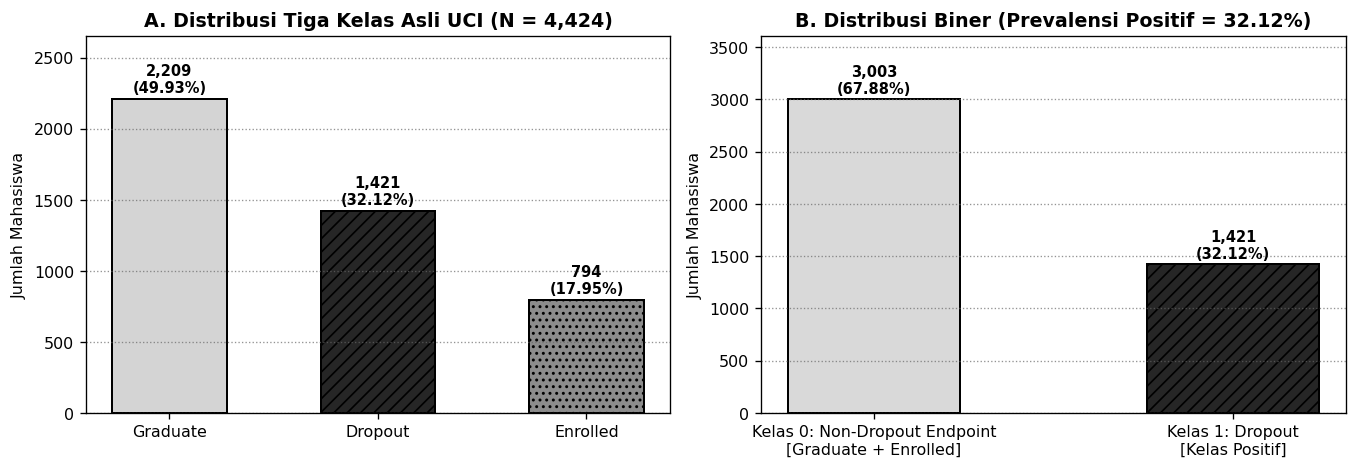

In [19]:
# Bagian 2.5 (Kode): Pemetaan Biner & Visualisasi Grayscale Distribusi Target
df_uci["obs_id"] = [f"OBS_{i:04d}" for i in range(1, len(df_uci) + 1)]
df_uci["label_dropout"] = (df_uci["Target"] == "Dropout").astype(int)

tabel_pemetaan_target = pd.DataFrame([
    {"Label asli": "Dropout", "Label biner": 1, "Jumlah": int((df_uci["Target"] == "Dropout").sum()), "Persentase (%)": round((df_uci["Target"] == "Dropout").mean() * 100, 2), "Makna Operasional": "Status tercatat Dropout pada endpoint pengamatan (Kelas Positif)"},
    {"Label asli": "Enrolled", "Label biner": 0, "Jumlah": int((df_uci["Target"] == "Enrolled").sum()), "Persentase (%)": round((df_uci["Target"] == "Enrolled").mean() * 100, 2), "Makna Operasional": "Masih terdaftar pada endpoint pengamatan (status pasca-jendela pengamatan tidak diketahui)"},
    {"Label asli": "Graduate", "Label biner": 0, "Jumlah": int((df_uci["Target"] == "Graduate").sum()), "Persentase (%)": round((df_uci["Target"] == "Graduate").mean() * 100, 2), "Makna Operasional": "Telah menyelesaikan studi pada endpoint pengamatan"},
])
display(tabel_pemetaan_target)

n_pos_total = int(df_uci["label_dropout"].sum())
n_neg_total = int((df_uci["label_dropout"] == 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.0))
urutan_3k = ["Graduate", "Dropout", "Enrolled"]
abu_3k = ["#d4d4d4", "#262626", "#8c8c8c"]
hatch_3k = ["", "///", "..."]
cnt_3k = [int((df_uci["Target"] == k).sum()) for k in urutan_3k]
bars1 = axes[0].bar(urutan_3k, cnt_3k, color=abu_3k, edgecolor="black", linewidth=1.2, width=0.55)
for b, ht in zip(bars1, hatch_3k):
    b.set_hatch(ht)
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width() / 2, h + 45, f"{h:,}\n({h/len(df_uci)*100:.2f}%)", ha="center", fontsize=8.8, fontweight="bold", color="black")
axes[0].set_title(f"A. Distribusi Tiga Kelas Asli UCI (N = {len(df_uci):,})", fontweight="bold")
axes[0].set_ylabel("Jumlah Mahasiswa")
axes[0].set_ylim(0, max(cnt_3k) * 1.20)
axes[0].grid(axis="y", linestyle=":", color="#666666", alpha=0.7)

urutan_2k = ["Kelas 0: Non-Dropout Endpoint\n[Graduate + Enrolled]", "Kelas 1: Dropout\n[Kelas Positif]"]
cnt_2k = [n_neg_total, n_pos_total]
bars2 = axes[1].bar(urutan_2k, cnt_2k, color=["#d9d9d9", "#262626"], edgecolor="black", linewidth=1.2, width=0.48)
bars2[1].set_hatch("///")
for b in bars2:
    h = b.get_height()
    axes[1].text(b.get_x() + b.get_width() / 2, h + 55, f"{h:,}\n({h/len(df_uci)*100:.2f}%)", ha="center", fontsize=8.8, fontweight="bold", color="black")
axes[1].set_title(f"B. Distribusi Biner (Prevalensi Positif = {n_pos_total/len(df_uci)*100:.2f}%)", fontweight="bold")
axes[1].set_ylabel("Jumlah Mahasiswa")
axes[1].set_ylim(0, max(cnt_2k) * 1.20)
axes[1].grid(axis="y", linestyle=":", color="#666666", alpha=0.7)

plt.tight_layout()
plt.savefig(LAMPIRAN_VIS_DIR / "gambar_01_distribusi_target_bw.png", dpi=300, bbox_inches="tight")
plt.show()


### 2.6 Titik Waktu Prediksi Akhir Semester Pertama dan Spesifikasi Fitur (28 Konservatif vs. 30 Pembanding)
* **Pengeluaran Mutlak Fitur Semester Kedua:** Enam fitur `Curricular units 2nd sem (...)` dikeluarkan seluruhnya karena belum tersedia pada akhir Semester Pertama.
* **Status `Debtor` dan `Tuition fees up to date`:** Dokumentasi UCI (#697) dan Realinho et al. (2022) mengelompokkan kedua atribut ini sebagai **fitur sosial-ekonomi**. Tidak terdapat bukti sumber resmi bahwa keduanya pasti dicatat setelah *dropout*, dan korelasi statistik yang tinggi dengan target tidak otomatis membuktikan *temporal leakage*. Namun, karena dokumentasi publik tidak mencantumkan *timestamp* per semester untuk kedua atribut tersebut:
  1. **Spesifikasi 28 Fitur Konservatif** dipilih sebagai konfigurasi utama berdasarkan keputusan kehati-hatian metodologis (*bukan* karena performanya paling tinggi).
  2. **Spesifikasi 30 Fitur Pembanding** (menambahkan `Debtor` dan `Tuition fees up to date`) dipertahankan sebagai analisis sensitivitas.


In [20]:
# Bagian 2.6 (Kode): Pemeriksaan Tabulasi Silang Debtor & Tuition Fees up to date
display(pd.crosstab(df_uci["Tuition fees up to date"], df_uci["Target"], margins=True))
display(pd.crosstab(df_uci["Debtor"], df_uci["Target"], margins=True))


Target,Dropout,Enrolled,Graduate,All
Tuition fees up to date,,,,
0,457,42,29,528
1,964,752,2180,3896
All,1421,794,2209,4424


Target,Dropout,Enrolled,Graduate,All
Debtor,,,,
0,1109,704,2108,3921
1,312,90,101,503
All,1421,794,2209,4424


---
## BAGIAN 3 & 4 — Pembagian Data (Penundaan Akses Label *Test Set*), Pipeline Preprocessing, CV, dan Uji Sensitivitas

Pada kode pembagian data di bawah ini, akses terhadap kolom target/label `Test Set` **ditunda sepenuhnya hingga Bagian 7.2**: pada tahap pengembangan model hanya matriks fitur `X_train`, `y_train`, `X_val`, dan `y_val` yang diekstraksi, sementara indeks uji disimpan tanpa membaca distribusi labelnya.


In [21]:
# Bagian 4.1 & 4.2 (Kode): Stratified Split 60/20/20 dengan Penundaan Akses Label Test Set hingga Bagian 7.2
idx_all = np.arange(len(df_uci))
idx_dev, idx_test_locked = train_test_split(
    idx_all, test_size=0.20, stratify=df_uci["Target"], random_state=SEED
)
df_dev_pool = df_uci.iloc[idx_dev].reset_index(drop=True)
df_train, df_val = train_test_split(
    df_dev_pool, test_size=0.25, stratify=df_dev_pool["Target"], random_state=SEED
)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)

# Hanya fitur prediktor yang disiapkan; label test tidak diakses sebelum Bagian 7.2
fitur_numerik = [
    "Application order",
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 1st sem (without evaluations)",
]
fitur_biner = [
    "Daytime/evening attendance",
    "Displaced",
    "Educational special needs",
    "Gender",
    "Scholarship holder",
    "International",
]
fitur_kategorikal_nominal = [
    "Marital status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
]
fitur_konservatif_28 = fitur_numerik + fitur_biner + fitur_kategorikal_nominal
assert len(fitur_konservatif_28) == 28

df_ringkasan_split = pd.DataFrame([
    {
        "Partisi": "Training Set (60%)",
        "Jumlah Observasi": len(df_train),
        "Proporsi Total": f"{len(df_train)/len(df_uci)*100:.2f}%",
        "Dropout (Kelas 1)": str(int((df_train["label_dropout"] == 1).sum())),
        "Prevalensi Positif": f"{df_train['label_dropout'].mean()*100:.2f}%",
        "Graduate": str(int((df_train["Target"] == "Graduate").sum())),
        "Enrolled": str(int((df_train["Target"] == "Enrolled").sum())),
    },
    {
        "Partisi": "Validation Set (20%)",
        "Jumlah Observasi": len(df_val),
        "Proporsi Total": f"{len(df_val)/len(df_uci)*100:.2f}%",
        "Dropout (Kelas 1)": str(int((df_val["label_dropout"] == 1).sum())),
        "Prevalensi Positif": f"{df_val['label_dropout'].mean()*100:.2f}%",
        "Graduate": str(int((df_val["Target"] == "Graduate").sum())),
        "Enrolled": str(int((df_val["Target"] == "Enrolled").sum())),
    },
    {
        "Partisi": "Test Set (20% - Indeks Terkunci)",
        "Jumlah Observasi": len(idx_test_locked),
        "Proporsi Total": f"{len(idx_test_locked)/len(df_uci)*100:.2f}%",
        "Dropout (Kelas 1)": "[Ditunda s.d. Evaluasi Akhir Bagian 7.2]",
        "Prevalensi Positif": "[Ditunda s.d. Evaluasi Akhir Bagian 7.2]",
        "Graduate": "[Ditunda]",
        "Enrolled": "[Ditunda]",
    },
])
df_ringkasan_split.to_csv(LAMPIRAN_TAB_DIR / "tabel_02_pembagian_data_split.csv", index=False)
display(df_ringkasan_split)


def bangun_preprocessor(num_c, bin_c, nom_c) -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_c),
            ("bin", Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))]), bin_c),
            ("nom", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), nom_c),
        ],
        remainder="drop",
    )


X_train = df_train[fitur_konservatif_28].copy()
y_train = df_train["label_dropout"].to_numpy()
X_val = df_val[fitur_konservatif_28].copy()
y_val = df_val["label_dropout"].to_numpy()

prep_cek = bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal).fit(X_train, y_train)
print(f"Dimensi matriks fitur tertransformasi pada Training Set: {X_train.shape[1]} kolom -> {prep_cek.transform(X_train).shape[1]} kolom.")


,Partisi,Jumlah Observasi,Proporsi Total,Dropout (Kelas 1),Prevalensi Positif,Graduate,Enrolled
0,Training Set (60%),2654,59.99%,853,32.14%,1325,476
1,Validation Set (20%),885,20.00%,284,32.09%,442,159
2,Test Set (20% - Indeks Terkunci),885,20.00%,[Ditunda s.d. Evaluasi Akhir Bagian 7.2],[Ditunda s.d. Evaluasi Akhir Bagian 7.2],[Ditunda],[Ditunda]


Dimensi matriks fitur tertransformasi pada Training Set: 28 kolom -> 213 kolom.


In [22]:
# Bagian 4.3 (Kode): 5-Fold Stratified CV di Train, Sensitivitas 22/28/30 Fitur, & Sensitivitas Eksklusi Enrolled
cv_internal = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def buat_logreg_base(c_val=1.0, cw=None):
    return Pipeline([
        ("prep", bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal)),
        ("clf", LogisticRegression(C=c_val, class_weight=cw, max_iter=2000, random_state=SEED)),
    ])


def buat_tree_base(max_d=5, min_leaf=20):
    return Pipeline([
        ("prep", bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal)),
        ("clf", DecisionTreeClassifier(max_depth=max_d, min_samples_leaf=min_leaf, random_state=SEED)),
    ])


kandidat_cv_train = {
    "1. Baseline Dummy (Prior)": Pipeline([("prep", bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal)), ("clf", DummyClassifier(strategy="prior", random_state=SEED))]),
    "2. Baseline Dummy (Stratified)": Pipeline([("prep", bangun_preprocessor(fitur_numerik, fitur_biner, fitur_kategorikal_nominal)), ("clf", DummyClassifier(strategy="stratified", random_state=SEED))]),
    "3. Logistic Regression Native (C=1.0)": buat_logreg_base(c_val=1.0, cw=None),
    "4. Logistic Regression Native (C=0.5)": buat_logreg_base(c_val=0.5, cw=None),
    "5. Logistic Regression Balanced (C=1.0)": buat_logreg_base(c_val=1.0, cw="balanced"),
    "6. Decision Tree Pruned (depth=5, leaf=20)": buat_tree_base(max_d=5, min_leaf=20),
    "7. Decision Tree Unpruned (depth=None)": buat_tree_base(max_d=None, min_leaf=1),
}

hasil_cv_rows = []
for nama_k, pipe_k in kandidat_cv_train.items():
    skor_cv = cross_validate(
        pipe_k, X_train, y_train, cv=cv_internal,
        scoring={"roc_auc": "roc_auc", "ap": "average_precision", "neg_brier": "neg_brier_score", "f1": "f1"},
    )
    hasil_cv_rows.append({
        "Model Kandidat (5-Fold CV di Train)": nama_k,
        "CV ROC-AUC (Mean ± SD)": f"{skor_cv['test_roc_auc'].mean():.4f} ± {skor_cv['test_roc_auc'].std():.4f}",
        "CV AP (Mean ± SD)": f"{skor_cv['test_ap'].mean():.4f} ± {skor_cv['test_ap'].std():.4f}",
        "CV Brier Score": round(-skor_cv["test_neg_brier"].mean(), 4),
        "CV F1@0.50": round(skor_cv["test_f1"].mean(), 4),
    })

df_hasil_cv = pd.DataFrame(hasil_cv_rows)
df_hasil_cv.to_csv(LAMPIRAN_TAB_DIR / "tabel_03_hasil_5fold_cv_train.csv", index=False)
print("=== 1. HASIL 5-FOLD STRATIFIED CROSS-VALIDATION PADA TRAINING SET ===")
display(df_hasil_cv)

fitur_num_enroll = ["Application order", "Previous qualification (grade)", "Admission grade", "Age at enrollment", "Unemployment rate", "Inflation rate", "GDP"]
skenario_fitur_cek = [
    ("Spesifikasi Pendaftaran Awal (22 Fitur)", fitur_num_enroll, fitur_biner, fitur_kategorikal_nominal),
    ("Spesifikasi Konservatif Akhir Sem 1 [DIPILIH] (28 Fitur)", fitur_numerik, fitur_biner, fitur_kategorikal_nominal),
    ("Spesifikasi Pembanding + Debtor & Tuition Fees (30 Fitur)", fitur_numerik, fitur_biner + ["Debtor", "Tuition fees up to date"], fitur_kategorikal_nominal),
]
baris_sens_fitur = []
for lbl_sf, nc_s, bc_s, mc_s in skenario_fitur_cek:
    kol_s = nc_s + bc_s + mc_s
    pipe_nat = Pipeline([("prep", bangun_preprocessor(nc_s, bc_s, mc_s)), ("clf", LogisticRegression(C=1.0, max_iter=2000, random_state=SEED))]).fit(df_train[kol_s], y_train)
    pipe_iso = CalibratedClassifierCV(
        estimator=Pipeline([("prep", bangun_preprocessor(nc_s, bc_s, mc_s)), ("clf", LogisticRegression(C=1.0, max_iter=2000, random_state=SEED))]),
        method="isotonic", cv=cv_internal,
    ).fit(df_train[kol_s], y_train)
    pr_nat = pipe_nat.predict_proba(df_val[kol_s])[:, 1]
    pr_iso = pipe_iso.predict_proba(df_val[kol_s])[:, 1]
    baris_sens_fitur.append({
        "Spesifikasi Fitur": lbl_sf,
        "Jml Fitur": len(kol_s),
        "Val ROC-AUC (Native)": round(roc_auc_score(y_val, pr_nat), 4),
        "Val AP (Native)": round(average_precision_score(y_val, pr_nat), 4),
        "Val ROC-AUC (Isotonic CV=5)": round(roc_auc_score(y_val, pr_iso), 4),
        "Val AP (Isotonic CV=5)": round(average_precision_score(y_val, pr_iso), 4),
        "Val Brier (Isotonic CV=5)": round(brier_score_loss(y_val, pr_iso), 4),
    })
df_sens_fitur = pd.DataFrame(baris_sens_fitur)
df_sens_fitur.to_csv(LAMPIRAN_TAB_DIR / "tabel_04_sensitivitas_22_28_30_fitur.csv", index=False)
print("\n=== 2. ANALISIS SENSITIVITAS SPESIFIKASI 22 VS 28 (KONSERVATIF) VS 30 (PEMBANDING) FITUR ===")
display(df_sens_fitur)

model_terlatih = {
    "Dummy (Prior)": kandidat_cv_train["1. Baseline Dummy (Prior)"].fit(X_train, y_train),
    "Dummy (Stratified)": kandidat_cv_train["2. Baseline Dummy (Stratified)"].fit(X_train, y_train),
    "LogReg (Native, C=1.0)": buat_logreg_base(c_val=1.0, cw=None).fit(X_train, y_train),
    "LogReg (Balanced, C=1.0)": buat_logreg_base(c_val=1.0, cw="balanced").fit(X_train, y_train),
    "LogReg + Platt/Sigmoid (CV=5)": CalibratedClassifierCV(estimator=buat_logreg_base(c_val=1.0, cw=None), method="sigmoid", cv=cv_internal).fit(X_train, y_train),
    "LogReg + Isotonic (CV=5)": CalibratedClassifierCV(estimator=buat_logreg_base(c_val=1.0, cw=None), method="isotonic", cv=cv_internal).fit(X_train, y_train),
    "Decision Tree Pruned (d=5)": buat_tree_base(max_d=5, min_leaf=20).fit(X_train, y_train),
    "Decision Tree + Platt/Sigmoid": CalibratedClassifierCV(estimator=buat_tree_base(max_d=5, min_leaf=20), method="sigmoid", cv=cv_internal).fit(X_train, y_train),
}
proba_val_dict = {nama: mdl.predict_proba(X_val)[:, 1] for nama, mdl in model_terlatih.items()}

# 3. Analisis Sensitivitas Terpisah: Dropout vs Graduate (Mengecualikan Enrolled)
df_sub_dg = df_uci[df_uci["Target"].isin(["Dropout", "Graduate"])].copy()
df_sub_dg["y_dg"] = (df_sub_dg["Target"] == "Dropout").astype(int)
sub_dev, _ = train_test_split(df_sub_dg, test_size=0.20, stratify=df_sub_dg["Target"], random_state=SEED)
sub_tr, sub_va = train_test_split(sub_dev, test_size=0.25, stratify=sub_dev["Target"], random_state=SEED)
mdl_sub_dg = CalibratedClassifierCV(estimator=buat_logreg_base(c_val=1.0, cw=None), method="isotonic", cv=cv_internal).fit(sub_tr[fitur_konservatif_28], sub_tr["y_dg"].to_numpy())
pv_sub_dg = mdl_sub_dg.predict_proba(sub_va[fitur_konservatif_28])[:, 1]
yv_sub_dg = sub_va["y_dg"].to_numpy()

pv_full_iso = proba_val_dict["LogReg + Isotonic (CV=5)"]
tn_f, fp_f, fn_f, tp_f = confusion_matrix(y_val, (pv_full_iso >= 0.50).astype(int)).ravel()
tn_s, fp_s, fn_s, tp_s = confusion_matrix(yv_sub_dg, (pv_sub_dg >= 0.50).astype(int)).ravel()

df_sens_enrolled = pd.DataFrame([
    {"Skema Populasi": "Kohort Penuh [UTAMA]: Dropout vs. (Enrolled + Graduate)", "N Total": len(df_uci), "n Val": len(y_val), "Prevalensi Positif": f"{y_val.mean()*100:.2f}%", "Val ROC-AUC": round(roc_auc_score(y_val, pv_full_iso), 4), "Val AP": round(average_precision_score(y_val, pv_full_iso), 4), "Val Brier": round(brier_score_loss(y_val, pv_full_iso), 4), "Precision@0.50": round(tp_f / (tp_f + fp_f), 4), "Recall@0.50": round(tp_f / (tp_f + fn_f), 4), "Specificity@0.50": round(tn_f / (tn_f + fp_f), 4)},
    {"Skema Populasi": "Skema Terpisah: Dropout vs. Graduate (Tanpa Enrolled)", "N Total": len(df_sub_dg), "n Val": len(yv_sub_dg), "Prevalensi Positif": f"{yv_sub_dg.mean()*100:.2f}%", "Val ROC-AUC": round(roc_auc_score(yv_sub_dg, pv_sub_dg), 4), "Val AP": round(average_precision_score(yv_sub_dg, pv_sub_dg), 4), "Val Brier": round(brier_score_loss(yv_sub_dg, pv_sub_dg), 4), "Precision@0.50": round(tp_s / (tp_s + fp_s), 4), "Recall@0.50": round(tp_s / (tp_s + fn_s), 4), "Specificity@0.50": round(tn_s / (tn_s + fp_s), 4)},
])
df_sens_enrolled.to_csv(LAMPIRAN_TAB_DIR / "tabel_05_sensitivitas_eksklusi_enrolled.csv", index=False)
print("\n=== 3. ANALISIS SENSITIVITAS TERPISAH: DROPOUT VS GRADUATE (TANPA ENROLLED) ===")
display(df_sens_enrolled)


=== 1. HASIL 5-FOLD STRATIFIED CROSS-VALIDATION PADA TRAINING SET ===


,Model Kandidat (5-Fold CV di Train),CV ROC-AUC (Mean ± SD),CV AP (Mean ± SD),CV Brier Score,CV F1@0.50
0,1. Baseline Dummy (Prior),0.5000 ± 0.0000,0.3214 ± 0.0008,0.2181,0.0000
1,2. Baseline Dummy (Stratified),0.4893 ± 0.0152,0.3174 ± 0.0065,0.4510,0.3148
2,3. Logistic Regression Native (C=1.0),0.8732 ± 0.0135,0.8114 ± 0.0137,0.1245,0.7018
3,4. Logistic Regression Native (C=0.5),0.8750 ± 0.0138,0.8129 ± 0.0142,0.1236,0.7050
4,5. Logistic Regression Balanced (C=1.0),0.8725 ± 0.0139,0.8086 ± 0.0154,0.1376,0.7129
5,"6. Decision Tree Pruned (depth=5, leaf=20)",0.8335 ± 0.0183,0.7387 ± 0.0196,0.1413,0.6619
6,7. Decision Tree Unpruned (depth=None),0.7177 ± 0.0163,0.5027 ± 0.0205,0.2483,0.6169



=== 2. ANALISIS SENSITIVITAS SPESIFIKASI 22 VS 28 (KONSERVATIF) VS 30 (PEMBANDING) FITUR ===


,Spesifikasi Fitur,Jml Fitur,Val ROC-AUC (Native),Val AP (Native),Val ROC-AUC (Isotonic CV=5),Val AP (Isotonic CV=5),Val Brier (Isotonic CV=5)
0,Spesifikasi Pendaftaran Awal (22 Fitur),22,0.7517,0.6234,0.7565,0.6247,0.1763
1,Spesifikasi Konservatif Akhir Sem 1 [DIPILIH] (28 Fitur),28,0.8852,0.8393,0.8868,0.8408,0.1136
2,Spesifikasi Pembanding + Debtor & Tuition Fees (30 Fitur),30,0.9092,0.8701,0.9096,0.8715,0.0987



=== 3. ANALISIS SENSITIVITAS TERPISAH: DROPOUT VS GRADUATE (TANPA ENROLLED) ===


,Skema Populasi,N Total,n Val,Prevalensi Positif,Val ROC-AUC,Val AP,Val Brier,Precision@0.50,Recall@0.50,Specificity@0.50
0,Kohort Penuh [UTAMA]: Dropout vs. (Enrolled + Graduate),4424,885,32.09%,0.8868,0.8408,0.1136,0.8107,0.6937,0.9235
1,Skema Terpisah: Dropout vs. Graduate (Tanpa Enrolled),3630,726,39.12%,0.9242,0.9127,0.0952,0.8626,0.7958,0.9186


**Catatan Kritis Hasil Sensitivitas:**
* Spesifikasi **30 fitur pembanding** memiliki metrik diskriminasi lebih tinggi (`Val ROC-AUC Isotonic = 0,9096`, `Val AP = 0,8715`) dibandingkan **28 fitur konservatif** (`Val ROC-AUC = 0,8868`, `Val AP = 0,8408`). Dengan demikian, **28 fitur dipilih bukan karena performanya tertinggi**, melainkan sebagai keputusan konservatif karena waktu pencatatan `Debtor` dan `Tuition fees up to date` per semester tidak terdokumentasi eksplisit.
* Pada `5-Fold CV`, `Decision Tree Unpruned` mengalami penurunan tajam (`CV ROC-AUC = 0,7177 ± 0,0163`, `CV Brier = 0,2483`) dibandingkan `Decision Tree Pruned` (`0,8335 ± 0,0183`) akibat *overfitting* daun pohon bermuatan sampel tunggal yang menghasilkan probabilitas ekstrem `0` atau `1`.


---
## BAGIAN 5 — Evaluasi Diskriminasi (`ROC-AUC` & `AP` Utama), Kalibrasi Probabilitas, Tiga *Confusion Matrix* (`0,30`, `0,50`, `0,70`), dan Kurva Evaluasi pada *Validation Set*

Pada studi ini **Average Precision (`AP`) digunakan sebagai metrik ringkasan utama kurva Precision–Recall**, sementara *Trapezoidal PR-AUC* tetap dihitung berdampingan untuk menunjukkan efek bias interpolasi linier pada model dengan skor probabilitas kembar (*ties*). Garis acuan *no-skill* sebesar prevalensi kelas positif (`0,3209` di *Validation Set*) merupakan *baseline* kurva PR dan ekspektasi `AP` pengklasifikasi acak, **bukan** nilai *Trapezoidal PR-AUC* pada pengklasifikasi konstan.


In [23]:
# Bagian 5.1 (Kode): Evaluasi Diskriminasi (ROC-AUC, AP Utama, Trapezoidal PR-AUC) & Kalibrasi (Brier, ECE, Per-Bin)
def hitung_ece_dan_tabel_bin(y_true: np.ndarray, y_prob: np.ndarray, n_bins: int = 10):
    batas_bin = np.linspace(0.0, 1.0, n_bins + 1)
    ece_total = 0.0
    catatan_bin = []
    n_total = len(y_true)
    for i in range(n_bins):
        b_bawah, b_atas = batas_bin[i], batas_bin[i + 1]
        if i < n_bins - 1:
            mask = (y_prob >= b_bawah) & (y_prob < b_atas)
            label_b = f"[{b_bawah:.1f}, {b_atas:.1f})"
        else:
            mask = (y_prob >= b_bawah) & (y_prob <= b_atas)
            label_b = f"[{b_bawah:.1f}, {b_atas:.1f}]"
        jml = int(np.sum(mask))
        if jml > 0:
            rata_pred = float(np.mean(y_prob[mask]))
            prop_aktual = float(np.mean(y_true[mask]))
            gap = abs(rata_pred - prop_aktual)
            ece_total += (jml / n_total) * gap
            catatan_bin.append({"Rentang Bin": label_b, "Jumlah Observasi": jml, "Rata-rata Prob Prediksi": round(rata_pred, 4), "Proporsi Aktual Dropout": round(prop_aktual, 4), "Selisih Absolut |Pred - Aktual|": round(gap, 4)})
        else:
            catatan_bin.append({"Rentang Bin": label_b, "Jumlah Observasi": 0, "Rata-rata Prob Prediksi": np.nan, "Proporsi Aktual Dropout": np.nan, "Selisih Absolut |Pred - Aktual|": np.nan})
    return float(ece_total), pd.DataFrame(catatan_bin)


rekap_model_val = []
for nama_m, pv_m in proba_val_dict.items():
    prec_c_m, rec_c_m, _ = precision_recall_curve(y_val, pv_m)
    trap_pr_m = auc(rec_c_m, prec_c_m)
    ap_m = average_precision_score(y_val, pv_m)
    ece10_m, _ = hitung_ece_dan_tabel_bin(y_val, pv_m, n_bins=10)
    ece5_m, _ = hitung_ece_dan_tabel_bin(y_val, pv_m, n_bins=5)
    rekap_model_val.append({
        "Model": nama_m,
        "ROC-AUC": round(roc_auc_score(y_val, pv_m), 4),
        "Average Precision (AP) [Utama]": round(ap_m, 4),
        "Trapezoidal PR-AUC": round(trap_pr_m, 4),
        "Selisih (Trap - AP)": round(trap_pr_m - ap_m, 4),
        "Brier Score": round(brier_score_loss(y_val, pv_m), 4),
        "ECE (10-Bin)": round(ece10_m, 4),
        "ECE (5-Bin)": round(ece5_m, 4),
        "F1 (t=0.50)": round(f1_score(y_val, (pv_m >= 0.50).astype(int), zero_division=0), 4),
    })

df_rekap_model_val = pd.DataFrame(rekap_model_val)
df_rekap_model_val.to_csv(LAMPIRAN_TAB_DIR / "tabel_06_perbandingan_diskriminasi_kalibrasi_val.csv", index=False)
display(df_rekap_model_val)

_, bin5_native = hitung_ece_dan_tabel_bin(y_val, proba_val_dict["LogReg (Native, C=1.0)"], n_bins=5)
_, bin5_bal = hitung_ece_dan_tabel_bin(y_val, proba_val_dict["LogReg (Balanced, C=1.0)"], n_bins=5)
_, bin5_sig = hitung_ece_dan_tabel_bin(y_val, proba_val_dict["LogReg + Platt/Sigmoid (CV=5)"], n_bins=5)
_, bin5_iso = hitung_ece_dan_tabel_bin(y_val, proba_val_dict["LogReg + Isotonic (CV=5)"], n_bins=5)

df_bin_ringkas = pd.DataFrame({
    "Bin Probabilitas": bin5_iso["Rentang Bin"],
    "n (Native)": bin5_native["Jumlah Observasi"],
    "Gap Native": bin5_native["Selisih Absolut |Pred - Aktual|"],
    "n (Balanced)": bin5_bal["Jumlah Observasi"],
    "Gap Balanced": bin5_bal["Selisih Absolut |Pred - Aktual|"],
    "n (Platt)": bin5_sig["Jumlah Observasi"],
    "Gap Platt": bin5_sig["Selisih Absolut |Pred - Aktual|"],
    "n (Isotonic)": bin5_iso["Jumlah Observasi"],
    "Pred Isotonic": bin5_iso["Rata-rata Prob Prediksi"],
    "Aktual Isotonic": bin5_iso["Proporsi Aktual Dropout"],
    "Gap Isotonic": bin5_iso["Selisih Absolut |Pred - Aktual|"],
})
display(df_bin_ringkas)

NAMA_MODEL_FINAL = "LogReg + Isotonic (CV=5)"
model_final_terkunci = model_terlatih[NAMA_MODEL_FINAL]
y_proba_val = proba_val_dict[NAMA_MODEL_FINAL]


,Model,ROC-AUC,Average Precision (AP) [Utama],Trapezoidal PR-AUC,Selisih (Trap - AP),Brier Score,ECE (10-Bin),ECE (5-Bin),F1 (t=0.50)
0,Dummy (Prior),0.5000,0.3209,0.6605,0.3395,0.2179,0.0005,0.0005,0.0000
1,Dummy (Stratified),0.4933,0.3181,0.4191,0.1010,0.4384,0.4384,0.4384,0.3071
2,"LogReg (Native, C=1.0)",0.8852,0.8393,0.8391,-0.0003,0.1142,0.0444,0.0304,0.7571
3,"LogReg (Balanced, C=1.0)",0.8844,0.8367,0.8365,-0.0003,0.1306,0.0975,0.0975,0.7353
4,LogReg + Platt/Sigmoid (CV=5),0.8854,0.8401,0.8398,-0.0003,0.1141,0.0356,0.0218,0.7500
5,LogReg + Isotonic (CV=5),0.8868,0.8408,0.8414,0.0006,0.1136,0.0270,0.0197,0.7476
6,Decision Tree Pruned (d=5),0.8499,0.7765,0.8014,0.0249,0.1284,0.0481,0.0402,0.7382
7,Decision Tree + Platt/Sigmoid,0.8638,0.8163,0.8177,0.0013,0.1230,0.0474,0.0474,0.7324


,Bin Probabilitas,n (Native),Gap Native,n (Balanced),Gap Balanced,n (Platt),Gap Platt,n (Isotonic),Pred Isotonic,Aktual Isotonic,Gap Isotonic
0,"[0.0, 0.2)",461,0.0147,344,0.0288,445,0.0002,448,0.0787,0.0848,0.0061
1,"[0.2, 0.4)",137,0.0487,147,0.1381,155,0.0554,150,0.2794,0.2200,0.0594
2,"[0.4, 0.6)",81,0.1035,114,0.2253,88,0.0588,89,0.5017,0.4607,0.0411
3,"[0.6, 0.8)",52,0.0550,92,0.2374,59,0.0013,64,0.6890,0.6875,0.0015
4,"[0.8, 1.0]",154,0.0147,188,0.0455,138,0.0391,134,0.9399,0.9552,0.0153


,Threshold,TP,FP,TN,FN,Accuracy,Precision,Recall,Specificity,F1,Flagged,Flagged_Pct
0,0.3000,232,111,490,52,0.8158,0.6764,0.8169,0.8153,0.7400,343,38.7600
1,0.5000,197,46,555,87,0.8497,0.8107,0.6937,0.9235,0.7476,243,27.4600
2,0.7000,148,10,591,136,0.8350,0.9367,0.5211,0.9834,0.6697,158,17.8500


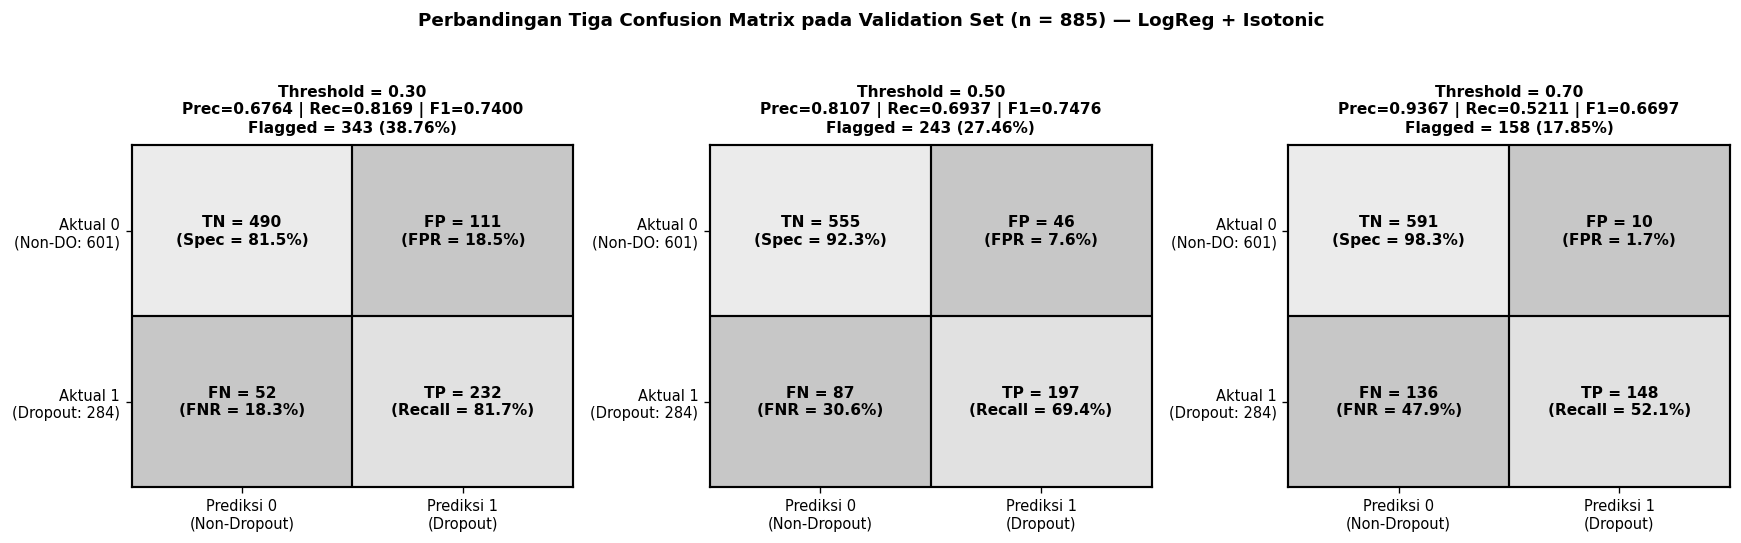

In [24]:
# Bagian 5.2 (Kode): Tiga Confusion Matrix (0.30, 0.50, 0.70) pada Validation Set dalam Format Grayscale Akademik
def evaluasi_satu_threshold(y_true: np.ndarray, y_prob: np.ndarray, threshold: float) -> dict:
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    n_obs = len(y_true)
    acc = (tp + tn) / n_obs if n_obs > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = (2.0 * prec * rec / (prec + rec)) if (prec + rec) > 0 else 0.0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0
    return {
        "Threshold": round(float(threshold), 6),
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
        "Accuracy": round(acc, 4), "Precision": round(prec, 4), "Recall": round(rec, 4),
        "Specificity": round(spec, 4), "F1": round(f1, 4), "FPR": round(fpr, 4), "FNR": round(fnr, 4),
        "Flagged": int(tp + fp), "Pred_Negatif": int(tn + fn),
        "Flagged_Pct": round((tp + fp) / n_obs * 100, 2),
    }


threshold_wajib = [0.30, 0.50, 0.70]
hasil_3_threshold = [evaluasi_satu_threshold(y_val, y_proba_val, t) for t in threshold_wajib]
df_3_threshold = pd.DataFrame(hasil_3_threshold)
df_3_threshold.to_csv(LAMPIRAN_TAB_DIR / "tabel_07_tiga_confusion_matrix_validasi.csv", index=False)
display(df_3_threshold[["Threshold", "TP", "FP", "TN", "FN", "Accuracy", "Precision", "Recall", "Specificity", "F1", "Flagged", "Flagged_Pct"]])

n_neg_val = int((y_val == 0).sum())
n_pos_val = int((y_val == 1).sum())

fig, axes = plt.subplots(1, 3, figsize=(14.6, 4.3))
for ax, row_t in zip(axes, hasil_3_threshold):
    cm_mat = np.array([[row_t["TN"], row_t["FP"]], [row_t["FN"], row_t["TP"]]])
    bg_mat = np.array([[0.92, 0.78], [0.78, 0.88]])
    ax.imshow(bg_mat, cmap="gray", vmin=0.0, vmax=1.0, aspect="auto")
    teks_sel = [
        [(0, 0, f"TN = {row_t['TN']}\n(Spec = {row_t['Specificity']*100:.1f}%)"),
         (0, 1, f"FP = {row_t['FP']}\n(FPR = {row_t['FPR']*100:.1f}%)")],
        [(1, 0, f"FN = {row_t['FN']}\n(FNR = {row_t['FNR']*100:.1f}%)"),
         (1, 1, f"TP = {row_t['TP']}\n(Recall = {row_t['Recall']*100:.1f}%)")],
    ]
    for baris_s in teks_sel:
        for r_i, c_i, txt_s in baris_s:
            ax.text(c_i, r_i, txt_s, ha="center", va="center", fontsize=9.2, fontweight="bold", color="black")
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Prediksi 0\n(Non-Dropout)", "Prediksi 1\n(Dropout)"], fontsize=8.8)
    ax.set_yticklabels([f"Aktual 0\n(Non-DO: {n_neg_val})", f"Aktual 1\n(Dropout: {n_pos_val})"], fontsize=8.8)
    for sp in ax.spines.values():
        sp.set_edgecolor("black")
        sp.set_linewidth(1.3)
    ax.axhline(0.5, color="black", linewidth=1.3)
    ax.axvline(0.5, color="black", linewidth=1.3)
    ax.set_title(
        f"Threshold = {row_t['Threshold']:.2f}\nPrec={row_t['Precision']:.4f} | Rec={row_t['Recall']:.4f} | F1={row_t['F1']:.4f}\nFlagged = {row_t['Flagged']} ({row_t['Flagged_Pct']:.2f}%)",
        fontsize=9.2, fontweight="bold", pad=8,
    )

plt.suptitle(f"Perbandingan Tiga Confusion Matrix pada Validation Set (n = {len(y_val)}) — LogReg + Isotonic", fontsize=11.0, fontweight="bold", y=1.04)
plt.tight_layout()
plt.savefig(LAMPIRAN_VIS_DIR / "gambar_02_tiga_confusion_matrix_bw.png", dpi=300, bbox_inches="tight")
plt.show()


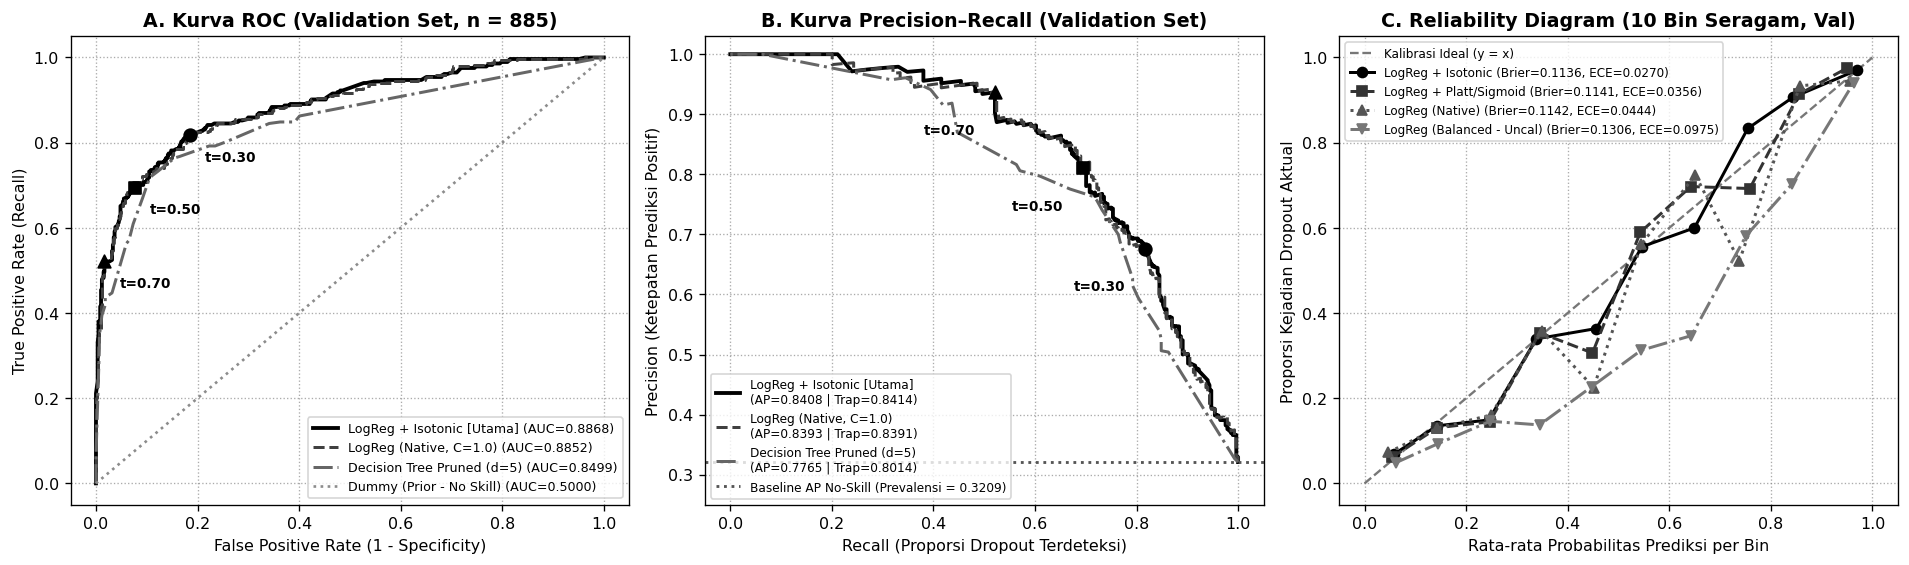

In [25]:
# Bagian 5.3 (Kode): Plot Grayscale Kurva ROC, Precision-Recall, dan Reliability Diagram (Pola Garis & Marker Berbeda)
prevalensi_pos_val = float(np.mean(y_val))

fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.8))

ax_roc = axes[0]
daftar_kurva_bw = [
    ("LogReg + Isotonic [Utama]", proba_val_dict["LogReg + Isotonic (CV=5)"], "black", "-", 2.3),
    ("LogReg (Native, C=1.0)", proba_val_dict["LogReg (Native, C=1.0)"], "#404040", "--", 1.8),
    ("Decision Tree Pruned (d=5)", proba_val_dict["Decision Tree Pruned (d=5)"], "#666666", "-.", 1.8),
    ("Dummy (Prior - No Skill)", proba_val_dict["Dummy (Prior)"], "#8c8c8c", ":", 1.6),
]
for lbl, pr_arr, col_bw, ls_bw, lw_bw in daftar_kurva_bw:
    fpr_c, tpr_c, _ = roc_curve(y_val, pr_arr)
    auc_c = roc_auc_score(y_val, pr_arr)
    ax_roc.plot(fpr_c, tpr_c, color=col_bw, linestyle=ls_bw, linewidth=lw_bw, label=f"{lbl} (AUC={auc_c:.4f})")

for r_t, mk_t in zip(hasil_3_threshold, ["o", "s", "^"]):
    ax_roc.scatter([r_t["FPR"]], [r_t["Recall"]], color="black", marker=mk_t, s=58, zorder=5)
    ax_roc.annotate(f"t={r_t['Threshold']:.2f}", (r_t["FPR"], r_t["Recall"]), xytext=(r_t["FPR"] + 0.03, r_t["Recall"] - 0.06), fontsize=8.2, fontweight="bold")

ax_roc.set_title(f"A. Kurva ROC (Validation Set, n = {len(y_val)})", fontweight="bold")
ax_roc.set_xlabel("False Positive Rate (1 - Specificity)")
ax_roc.set_ylabel("True Positive Rate (Recall)")
ax_roc.legend(loc="lower right", fontsize=7.6)
ax_roc.grid(True, linestyle=":", color="#888888", alpha=0.7)

ax_pr = axes[1]
for lbl, pr_arr, col_bw, ls_bw, lw_bw in daftar_kurva_bw[:3]:
    prec_c, rec_c, _ = precision_recall_curve(y_val, pr_arr)
    ap_c = average_precision_score(y_val, pr_arr)
    trap_c = auc(rec_c, prec_c)
    ax_pr.plot(rec_c, prec_c, color=col_bw, linestyle=ls_bw, linewidth=lw_bw, label=f"{lbl}\n(AP={ap_c:.4f} | Trap={trap_c:.4f})")

ax_pr.axhline(prevalensi_pos_val, color="#555555", linestyle=":", linewidth=1.7, label=f"Baseline AP No-Skill (Prevalensi = {prevalensi_pos_val:.4f})")
for r_t, mk_t in zip(hasil_3_threshold, ["o", "s", "^"]):
    ax_pr.scatter([r_t["Recall"]], [r_t["Precision"]], color="black", marker=mk_t, s=58, zorder=5)
    ax_pr.annotate(f"t={r_t['Threshold']:.2f}", (r_t["Recall"], r_t["Precision"]), xytext=(r_t["Recall"] - 0.14, r_t["Precision"] - 0.07), fontsize=8.2, fontweight="bold")

ax_pr.set_title("B. Kurva Precision–Recall (Validation Set)", fontweight="bold")
ax_pr.set_xlabel("Recall (Proporsi Dropout Terdeteksi)")
ax_pr.set_ylabel("Precision (Ketepatan Prediksi Positif)")
ax_pr.set_ylim(0.25, 1.03)
ax_pr.legend(loc="lower left", fontsize=7.3)
ax_pr.grid(True, linestyle=":", color="#888888", alpha=0.7)

ax_cal = axes[2]
ax_cal.plot([0, 1], [0, 1], color="#777777", linestyle="--", linewidth=1.4, label="Kalibrasi Ideal (y = x)")
daftar_kal_bw = [
    ("LogReg + Isotonic", proba_val_dict["LogReg + Isotonic (CV=5)"], "black", "o", "-"),
    ("LogReg + Platt/Sigmoid", proba_val_dict["LogReg + Platt/Sigmoid (CV=5)"], "#333333", "s", "--"),
    ("LogReg (Native)", proba_val_dict["LogReg (Native, C=1.0)"], "#555555", "^", ":"),
    ("LogReg (Balanced - Uncal)", proba_val_dict["LogReg (Balanced, C=1.0)"], "#777777", "v", "-."),
]
for lbl_k, pr_k, col_k, mk_k, ls_k in daftar_kal_bw:
    prob_true_k, prob_pred_k = calibration_curve(y_val, pr_k, n_bins=10, strategy="uniform")
    brier_k = brier_score_loss(y_val, pr_k)
    ece_k, _ = hitung_ece_dan_tabel_bin(y_val, pr_k, n_bins=10)
    ax_cal.plot(prob_pred_k, prob_true_k, marker=mk_k, color=col_k, linestyle=ls_k, linewidth=1.8, label=f"{lbl_k} (Brier={brier_k:.4f}, ECE={ece_k:.4f})")

ax_cal.set_title("C. Reliability Diagram (10 Bin Seragam, Val)", fontweight="bold")
ax_cal.set_xlabel("Rata-rata Probabilitas Prediksi per Bin")
ax_cal.set_ylabel("Proporsi Kejadian Dropout Aktual")
ax_cal.legend(loc="upper left", fontsize=7.2)
ax_cal.grid(True, linestyle=":", color="#888888", alpha=0.7)

plt.tight_layout()
plt.savefig(LAMPIRAN_VIS_DIR / "gambar_03_kurva_roc_pr_reliability_bw.png", dpi=300, bbox_inches="tight")
plt.show()


---
## BAGIAN 6 — Matriks Biaya Kesalahan, Skenario Kapasitas Simulasi, dan Pemilihan *Threshold* Operasional (`t* = 0,3483` Eksak vs. Alternatif Grid `0,34` & `0,35`)

* **Skenario Matriks Biaya Relatif:** $C_{\text{FP}} = 1$ satuan biaya dan $C_{\text{FN}} \in \{1, 2, 4, 8\}$ satuan biaya (skenario acuan $1:4$; nilai relatif simulasi, bukan nominal finansial aktual).
* **Skenario Simulasi Kapasitas Tindak Lanjut:** `25%`, `30%`, `35%` (*skenario simulasi kapasitas acuan* — **bukan kapasitas nyata konselor/DPA institusi**), `40%`, dan tanpa batas (`100%`).
* **Konsistensi Rekomendasi Berdasarkan *Validation Set*:** Di dalam kendala kapasitas simulasi `<= 35%` (`<= 309` observasi validasi), pencarian eksak pada seluruh titik probabilitas unik menemukan **minimum biaya eksak pada `t* = 0,3483` (`342 satuan`, `FP = 86`, `Flagged = 306` / `34,58%`)**, yang secara matematis lebih rendah biayanya dibandingkan kandidat pembulatan grid `0,01` pada **`t = 0,34` (`344 satuan`, `FP = 88`, `Flagged = 308` / `34,80%`)** maupun `t = 0,35` (`346 satuan`). Oleh sebab itu, **`t* = 0,3483` ditetapkan sebagai rekomendasi utama minimum biaya eksak**, sedangkan `0,34` dan `0,35` dipertahankan sebagai alternatif dan analisis sensitivitas pada grid `0,01`.


,Rasio Biaya (FP : FN),Ambang Teoretis Bayes,Biaya t=0.30,Biaya t=0.50,Biaya t=0.70,t* Min Eksak,Biaya Min Eksak,Flagged Eksak,t* Min Grid 0.01,Biaya Min Grid
0,1 : 1 (Setara),0.5000,163,133,146,0.5309,127,223 (25.20%),0.5300,127
1,1 : 2 (Asimetris Ringan),0.3333,215,220,282,0.3069,212,334 (37.74%),0.4400,215
2,1 : 4 (Skenario Biaya Acuan),0.2000,319,394,554,0.2682,312,371 (41.92%),0.2600,313
3,1 : 8 (Proteksi Agresif),0.1111,527,742,1098,0.0946,453,584 (65.99%),0.0900,465


,Skenario Simulasi Kapasitas,Maks Flagged (Val),t* Eksak,Biaya Eksak (1:4),Flagged Eksak,Precision (Eksak),Recall (Eksak),Specificity (Eksak),F1 (Eksak),t* Grid 0.01,Biaya Grid (1:4),Flagged Grid
0,Simulasi Kapasitas 25%,221,0.5452,416,220 (24.86%),0.8545,0.6620,0.9468,0.7460,0.5500,423,217 (24.52%)
1,Simulasi Kapasitas 30%,265,0.4599,381,265 (29.94%),0.7698,0.7183,0.8985,0.7432,0.4600,385,264 (29.83%)
2,Simulasi Kapasitas Acuan 35%,309,0.3483,342,306 (34.58%),0.7190,0.7746,0.8569,0.7458,0.3400,344,308 (34.80%)
3,Simulasi Kapasitas 40%,354,0.2990,317,346 (39.10%),0.6734,0.8204,0.8120,0.7397,0.3000,319,343 (38.76%)
4,Tanpa Kendala Kapasitas (100%),885,0.2682,312,371 (41.92%),0.6442,0.8415,0.7804,0.7298,0.2600,313,372 (42.03%)


,Peran Kandidat pada Validation Set,Threshold,TP,FP,TN,FN,Precision,Recall,Specificity,F1,Flagged,Flagged_Pct,Cost_1_4
0,Rekomendasi Utama: Minimum Biaya Eksak (<=35%),0.3483,220.0000,86.0000,515.0000,64.0000,0.7190,0.7746,0.8569,0.7458,306.0000,34.5800,342.0000
1,Alternatif Grid 0.01 (Sensitivitas Bawah),0.3400,220.0000,88.0000,513.0000,64.0000,0.7143,0.7746,0.8536,0.7432,308.0000,34.8000,344.0000
2,Sensitivitas Grid 0.35 (Pembulatan ke Atas),0.3500,219.0000,86.0000,515.0000,65.0000,0.7180,0.7711,0.8569,0.7436,305.0000,34.4600,346.0000
3,Batas Bawah Eksak Mulai Memenuhi <=309 Mhs,0.3389,220.0000,89.0000,512.0000,64.0000,0.7120,0.7746,0.8519,0.7420,309.0000,34.9200,345.0000


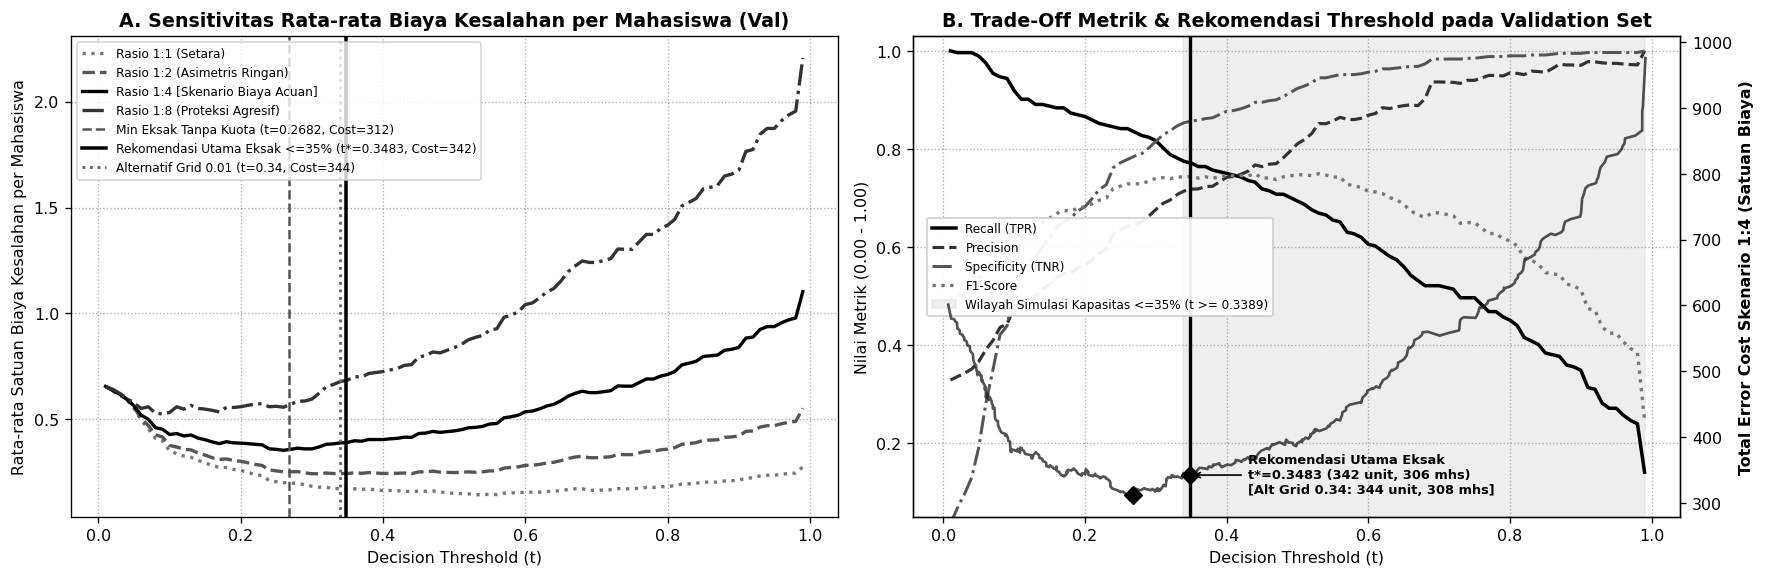

  model_utama                         : LogReg + Isotonic (CV=5)
  spesifikasi_fitur_utama             : 28 Fitur Konservatif Akhir Semester Pertama
  rasio_biaya_acuan                   : {'Cost_FP': 1, 'Cost_FN': 4}
  simulasi_kapasitas_acuan_pct        : 35.0
  threshold_final_utama_eksak         : 0.348279
  threshold_final_utama_eksak_4des    : 0.3483
  threshold_alternatif_grid_001       : 0.34


In [26]:
# Bagian 6.1 - 6.4 (Kode): Pencarian Eksak & Grid 0.01 pada Validation Set, Penguncian t* = 0.3483, & Plot Grayscale
grid_001 = np.round(np.arange(0.01, 1.00, 0.01), 2)
titik_unik_prob = np.sort(np.unique(y_proba_val))


def bangun_tabel_pencarian_threshold(daftar_t, y_true, y_prob):
    baris = []
    for t in daftar_t:
        ev = evaluasi_satu_threshold(y_true, y_prob, float(t))
        fp, fn = ev["FP"], ev["FN"]
        ev["Cost_1_1"] = int(1 * fp + 1 * fn)
        ev["Cost_1_2"] = int(1 * fp + 2 * fn)
        ev["Cost_1_4"] = int(1 * fp + 4 * fn)
        ev["Cost_1_8"] = int(1 * fp + 8 * fn)
        baris.append(ev)
    return pd.DataFrame(baris)


df_grid_val = bangun_tabel_pencarian_threshold(grid_001, y_val, y_proba_val)
df_eksak_val = bangun_tabel_pencarian_threshold(titik_unik_prob, y_val, y_proba_val)

rekap_sensitivitas_biaya = []
for kol_c, rasio_str, c_fp, c_fn in [
    ("Cost_1_1", "1 : 1 (Setara)", 1, 1),
    ("Cost_1_2", "1 : 2 (Asimetris Ringan)", 1, 2),
    ("Cost_1_4", "1 : 4 (Skenario Biaya Acuan)", 1, 4),
    ("Cost_1_8", "1 : 8 (Proteksi Agresif)", 1, 8),
]:
    r_grid = df_grid_val.sort_values([kol_c, "Flagged"]).iloc[0]
    r_eksak = df_eksak_val.sort_values([kol_c, "Flagged"]).iloc[0]
    rekap_sensitivitas_biaya.append({
        "Rasio Biaya (FP : FN)": rasio_str,
        "Ambang Teoretis Bayes": round(c_fp / (c_fp + c_fn), 4),
        "Biaya t=0.30": int(df_grid_val.loc[df_grid_val["Threshold"] == 0.30, kol_c].iloc[0]),
        "Biaya t=0.50": int(df_grid_val.loc[df_grid_val["Threshold"] == 0.50, kol_c].iloc[0]),
        "Biaya t=0.70": int(df_grid_val.loc[df_grid_val["Threshold"] == 0.70, kol_c].iloc[0]),
        "t* Min Eksak": round(float(r_eksak["Threshold"]), 4),
        "Biaya Min Eksak": int(r_eksak[kol_c]),
        "Flagged Eksak": f"{int(r_eksak['Flagged'])} ({r_eksak['Flagged_Pct']:.2f}%)",
        "t* Min Grid 0.01": round(float(r_grid["Threshold"]), 2),
        "Biaya Min Grid": int(r_grid[kol_c]),
    })
df_sensitivitas_biaya = pd.DataFrame(rekap_sensitivitas_biaya)
df_sensitivitas_biaya.to_csv(LAMPIRAN_TAB_DIR / "tabel_08_sensitivitas_rasio_biaya_val.csv", index=False)
display(df_sensitivitas_biaya)

rekap_kapasitas = []
for nama_kap, persen_kap in [
    ("Simulasi Kapasitas 25%", 25),
    ("Simulasi Kapasitas 30%", 30),
    ("Simulasi Kapasitas Acuan 35%", 35),
    ("Simulasi Kapasitas 40%", 40),
    ("Tanpa Kendala Kapasitas (100%)", 100),
]:
    batas_mhs = int(np.floor(len(y_val) * persen_kap / 100.0))
    opt_eksak = df_eksak_val[df_eksak_val["Flagged"] <= batas_mhs].sort_values(["Cost_1_4", "Flagged"]).iloc[0]
    opt_grid = df_grid_val[df_grid_val["Flagged"] <= batas_mhs].sort_values(["Cost_1_4", "Flagged"]).iloc[0]
    rekap_kapasitas.append({
        "Skenario Simulasi Kapasitas": nama_kap,
        "Maks Flagged (Val)": batas_mhs,
        "t* Eksak": round(float(opt_eksak["Threshold"]), 4),
        "Biaya Eksak (1:4)": int(opt_eksak["Cost_1_4"]),
        "Flagged Eksak": f"{int(opt_eksak['Flagged'])} ({opt_eksak['Flagged_Pct']:.2f}%)",
        "Precision (Eksak)": opt_eksak["Precision"],
        "Recall (Eksak)": opt_eksak["Recall"],
        "Specificity (Eksak)": opt_eksak["Specificity"],
        "F1 (Eksak)": opt_eksak["F1"],
        "t* Grid 0.01": round(float(opt_grid["Threshold"]), 2),
        "Biaya Grid (1:4)": int(opt_grid["Cost_1_4"]),
        "Flagged Grid": f"{int(opt_grid['Flagged'])} ({opt_grid['Flagged_Pct']:.2f}%)",
    })
df_simulasi_kapasitas = pd.DataFrame(rekap_kapasitas)
df_simulasi_kapasitas.to_csv(LAMPIRAN_TAB_DIR / "tabel_09_simulasi_kapasitas_val.csv", index=False)
display(df_simulasi_kapasitas)

BATAS_MHS_35 = int(np.floor(len(y_val) * 0.35))
baris_min_tanpa_batas_eksak = df_eksak_val.sort_values(["Cost_1_4", "Flagged"]).iloc[0]
baris_min_tanpa_batas_grid = df_grid_val.sort_values(["Cost_1_4", "Flagged"]).iloc[0]

sub_eksak_35 = df_eksak_val[df_eksak_val["Flagged"] <= BATAS_MHS_35]
baris_batas_bawah_eksak_35 = sub_eksak_35.sort_values("Threshold").iloc[0]
baris_opt_eksak_35 = sub_eksak_35.sort_values(["Cost_1_4", "Flagged"]).iloc[0]
baris_opt_grid_034 = df_grid_val[df_grid_val["Flagged"] <= BATAS_MHS_35].sort_values(["Cost_1_4", "Flagged"]).iloc[0]
baris_grid_035 = df_grid_val[df_grid_val["Threshold"] == 0.35].iloc[0]

# Penetapan threshold final utama berdasarkan minimum biaya eksak di Validation Set pada skenario kapasitas 35%
T_MIN_TANPA_BATAS_EKSAK = float(baris_min_tanpa_batas_eksak["Threshold"])
T_MIN_TANPA_BATAS_GRID = float(baris_min_tanpa_batas_grid["Threshold"])
T_BATAS_BAWAH_EKSAK_35 = float(baris_batas_bawah_eksak_35["Threshold"])
T_FINAL_EKSAK_35 = float(baris_opt_eksak_35["Threshold"])
T_ALT_GRID_034 = float(baris_opt_grid_034["Threshold"])

df_banding_kandidat_35 = pd.DataFrame([
    {"Peran Kandidat pada Validation Set": "Rekomendasi Utama: Minimum Biaya Eksak (<=35%)", **baris_opt_eksak_35[["Threshold", "TP", "FP", "TN", "FN", "Precision", "Recall", "Specificity", "F1", "Flagged", "Flagged_Pct", "Cost_1_4"]].to_dict()},
    {"Peran Kandidat pada Validation Set": "Alternatif Grid 0.01 (Sensitivitas Bawah)", **baris_opt_grid_034[["Threshold", "TP", "FP", "TN", "FN", "Precision", "Recall", "Specificity", "F1", "Flagged", "Flagged_Pct", "Cost_1_4"]].to_dict()},
    {"Peran Kandidat pada Validation Set": "Sensitivitas Grid 0.35 (Pembulatan ke Atas)", **baris_grid_035[["Threshold", "TP", "FP", "TN", "FN", "Precision", "Recall", "Specificity", "F1", "Flagged", "Flagged_Pct", "Cost_1_4"]].to_dict()},
    {"Peran Kandidat pada Validation Set": "Batas Bawah Eksak Mulai Memenuhi <=309 Mhs", **baris_batas_bawah_eksak_35[["Threshold", "TP", "FP", "TN", "FN", "Precision", "Recall", "Specificity", "F1", "Flagged", "Flagged_Pct", "Cost_1_4"]].to_dict()},
])
df_banding_kandidat_35.to_csv(LAMPIRAN_TAB_DIR / "tabel_10_perbandingan_eksak_03483_vs_grid.csv", index=False)
display(df_banding_kandidat_35)

fig, axes = plt.subplots(1, 2, figsize=(14.8, 4.9))
ax1 = axes[0]
for kol_c, lbl_c, col_c, ls_c in [
    ("Cost_1_1", "Rasio 1:1 (Setara)", "#777777", ":"),
    ("Cost_1_2", "Rasio 1:2 (Asimetris Ringan)", "#555555", "--"),
    ("Cost_1_4", "Rasio 1:4 [Skenario Biaya Acuan]", "black", "-"),
    ("Cost_1_8", "Rasio 1:8 (Proteksi Agresif)", "#333333", "-."),
]:
    ax1.plot(df_grid_val["Threshold"], df_grid_val[kol_c] / len(y_val), color=col_c, linestyle=ls_c, linewidth=2.0, label=lbl_c)

ax1.axvline(T_MIN_TANPA_BATAS_EKSAK, color="#555555", linestyle="--", linewidth=1.5, label=f"Min Eksak Tanpa Kuota (t={T_MIN_TANPA_BATAS_EKSAK:.4f}, Cost=312)")
ax1.axvline(T_FINAL_EKSAK_35, color="black", linestyle="-", linewidth=2.1, label=f"Rekomendasi Utama Eksak <=35% (t*={T_FINAL_EKSAK_35:.4f}, Cost=342)")
ax1.axvline(T_ALT_GRID_034, color="#666666", linestyle=":", linewidth=1.7, label=f"Alternatif Grid 0.01 (t={T_ALT_GRID_034:.2f}, Cost=344)")
ax1.set_title("A. Sensitivitas Rata-rata Biaya Kesalahan per Mahasiswa (Val)", fontweight="bold")
ax1.set_xlabel("Decision Threshold (t)")
ax1.set_ylabel("Rata-rata Satuan Biaya Kesalahan per Mahasiswa")
ax1.legend(loc="upper left", fontsize=7.3)
ax1.grid(True, linestyle=":", color="#888888", alpha=0.7)

ax2 = axes[1]
ax2.plot(df_grid_val["Threshold"], df_grid_val["Recall"], color="black", linestyle="-", linewidth=2.1, label="Recall (TPR)")
ax2.plot(df_grid_val["Threshold"], df_grid_val["Precision"], color="#333333", linestyle="--", linewidth=1.9, label="Precision")
ax2.plot(df_grid_val["Threshold"], df_grid_val["Specificity"], color="#555555", linestyle="-.", linewidth=1.8, label="Specificity (TNR)")
ax2.plot(df_grid_val["Threshold"], df_grid_val["F1"], color="#777777", linestyle=":", linewidth=2.0, label="F1-Score")
ax2.axvspan(T_BATAS_BAWAH_EKSAK_35, 0.99, color="#e6e6e6", alpha=0.65, label=f"Wilayah Simulasi Kapasitas <=35% (t >= {T_BATAS_BAWAH_EKSAK_35:.4f})")
ax2.axvline(T_FINAL_EKSAK_35, color="black", linestyle="-", linewidth=2.0)

ax2_cost = ax2.twinx()
ax2_cost.plot(df_eksak_val["Threshold"], df_eksak_val["Cost_1_4"], color="#1a1a1a", linewidth=1.6, alpha=0.75)
ax2_cost.set_ylabel("Total Error Cost Skenario 1:4 (Satuan Biaya)", fontweight="bold")
ax2_cost.scatter([T_MIN_TANPA_BATAS_EKSAK, T_FINAL_EKSAK_35], [int(baris_min_tanpa_batas_eksak["Cost_1_4"]), int(baris_opt_eksak_35["Cost_1_4"])], color="black", marker="D", s=55, zorder=6)
ax2_cost.annotate(
    f"Rekomendasi Utama Eksak\nt*={T_FINAL_EKSAK_35:.4f} (342 unit, 306 mhs)\n[Alt Grid 0.34: 344 unit, 308 mhs]",
    (T_FINAL_EKSAK_35, int(baris_opt_eksak_35["Cost_1_4"])), xytext=(0.43, int(baris_opt_eksak_35["Cost_1_4"]) - 28),
    arrowprops=dict(arrowstyle="->", color="black"), fontsize=7.8, fontweight="bold",
)
ax2.set_title("B. Trade-Off Metrik & Rekomendasi Threshold pada Validation Set", fontweight="bold")
ax2.set_xlabel("Decision Threshold (t)")
ax2.set_ylabel("Nilai Metrik (0.00 - 1.00)")
ax2.set_ylim(0.05, 1.03)
ax2.legend(loc="center left", bbox_to_anchor=(0.01, 0.52), fontsize=7.2, framealpha=0.94)
ax2.grid(True, linestyle=":", color="#888888", alpha=0.7)

plt.tight_layout()
plt.savefig(LAMPIRAN_VIS_DIR / "gambar_04_optimasi_threshold_biaya_kapasitas_bw.png", dpi=300, bbox_inches="tight")
plt.show()

KONFIGURASI_FINAL_TERKUNCI = {
    "model_utama": NAMA_MODEL_FINAL,
    "spesifikasi_fitur_utama": "28 Fitur Konservatif Akhir Semester Pertama",
    "rasio_biaya_acuan": {"Cost_FP": 1, "Cost_FN": 4},
    "simulasi_kapasitas_acuan_pct": 35.0,
    "threshold_final_utama_eksak": T_FINAL_EKSAK_35,
    "threshold_final_utama_eksak_4des": round(T_FINAL_EKSAK_35, 4),
    "threshold_alternatif_grid_001": T_ALT_GRID_034,
}
for k, v in KONFIGURASI_FINAL_TERKUNCI.items():
    print(f"  {k:36s}: {v}")


In [27]:
# Bagian 7.1 (Kode): Error Analysis 4 Kasus Penting di Validation Set pada Threshold Utama t* = 0.3483
kamus_prodi_uci = {
    33: "Biofuel Production Tech.", 171: "Animation & Multimedia Design", 8014: "Social Service (Evening)",
    9003: "Agronomy", 9070: "Communication Design", 9085: "Veterinary Nursing", 9119: "Informatics Engineering",
    9130: "Equinculture", 9147: "Management", 9238: "Social Service", 9254: "Tourism", 9500: "Nursing",
    9556: "Oral Hygiene", 9670: "Advertising & Marketing Mgmt", 9773: "Journalism & Communication",
    9853: "Basic Education", 9991: "Management (Evening)",
}

df_val_analisis = df_val.copy()
df_val_analisis["prob_prediksi"] = np.round(y_proba_val, 4)
df_val_analisis["pred_t030"] = (y_proba_val >= 0.30).astype(int)
df_val_analisis["pred_t_eksak_03483"] = (y_proba_val >= T_FINAL_EKSAK_35).astype(int)
df_val_analisis["pred_t050"] = (y_proba_val >= 0.50).astype(int)
df_val_analisis["pred_t070"] = (y_proba_val >= 0.70).astype(int)
df_val_analisis["nama_prodi"] = df_val_analisis["Course"].map(kamus_prodi_uci).fillna("Other")

id_kasus_pilihan = ["OBS_4422", "OBS_2705", "OBS_1631", "OBS_4092"]
df_4_kasus = df_val_analisis[df_val_analisis["obs_id"].isin(id_kasus_pilihan)].set_index("obs_id").loc[id_kasus_pilihan].reset_index()
kol_err = [
    "obs_id", "Target", "label_dropout", "prob_prediksi",
    "pred_t030", "pred_t_eksak_03483", "pred_t050", "pred_t070",
    "nama_prodi", "Age at enrollment", "Gender", "Scholarship holder",
    "Admission grade", "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
]
df_4_kasus[kol_err].to_csv(LAMPIRAN_TAB_DIR / "tabel_11_empat_kasus_error_analysis_val.csv", index=False)
display(df_4_kasus[kol_err])

fp_val_eksak = df_val_analisis[(df_val_analisis["label_dropout"] == 0) & (df_val_analisis["pred_t_eksak_03483"] == 1)]
dist_fp_eksak = fp_val_eksak["Target"].value_counts()
print(
    f"Komposisi {len(fp_val_eksak)} False Positive Validation pada t* eksak = {T_FINAL_EKSAK_35:.4f}: "
    f"Enrolled = {dist_fp_eksak.get('Enrolled', 0)} ({dist_fp_eksak.get('Enrolled', 0)/len(fp_val_eksak)*100:.1f}%), "
    f"Graduate = {dist_fp_eksak.get('Graduate', 0)} ({dist_fp_eksak.get('Graduate', 0)/len(fp_val_eksak)*100:.1f}%)."
)


,obs_id,Target,label_dropout,prob_prediksi,pred_t030,pred_t_eksak_03483,pred_t050,pred_t070,nama_prodi,Age at enrollment,Gender,Scholarship holder,Admission grade,Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade)
0,OBS_4422,Dropout,1,0.0482,0,0,0,0,Nursing,30,0,1,149.5000,7,8,7,14.9125
1,OBS_2705,Enrolled,0,0.9867,1,1,1,1,Advertising & Marketing Mgmt,19,1,0,108.0000,5,10,0,0.0000
2,OBS_1631,Graduate,0,0.7343,1,1,1,1,Equinculture,53,1,0,120.0000,5,9,4,12.2500
3,OBS_4092,Dropout,1,0.4982,1,1,0,0,Management (Evening),29,0,0,135.5000,5,15,2,13.2500


Komposisi 86 False Positive Validation pada t* eksak = 0.3483: Enrolled = 49 (57.0%), Graduate = 37 (43.0%).


### 7.2 Evaluasi Akhir Satu Kali pada *Test Set* Menggunakan Konfigurasi yang Ditetapkan dari *Validation Set*
*Test Set* baru diakses pada sel berikut untuk mengevaluasi konfigurasi utama **`t* eksak = 0,3483`**, didampingi pelaporan alternatif grid `0,34` serta pembanding pra-ditetapkan `0,50`. **Pemilihan rekomendasi utama tidak diubah oleh hasil *Test Set*** (meskipun pada sampel uji tertentu grid `0,34` kebetulan berselisih beberapa satuan biaya terhadap `0,3483`, keputusan metodologis yang sah wajib tetap berpegang pada hasil *Validation Set*).


Test Set dibuka pada evaluasi akhir: n = 885 (Dropout = 284 [32.09%], Non-Dropout = 601 [67.91%])


,Skema Evaluasi,Threshold_4Des,TP,FP,TN,FN,Accuracy,Precision,Recall,Specificity,F1,Flagged,Flagged_Pct,Error_Cost_1_4,ROC_AUC,AP,Trap_PR_AUC,Brier_Score,ECE_10Bin
0,Validation — Rekomendasi Utama Eksak (t*=0.3483),0.3483,220,86,515,64,0.8305,0.7190,0.7746,0.8569,0.7458,306,34.5800,342,0.8868,0.8408,0.8414,0.1136,0.0270
1,Test Final — Rekomendasi Utama Eksak (t*=0.3483),0.3483,207,76,525,77,0.8271,0.7314,0.7289,0.8735,0.7302,283,31.9800,384,0.8898,0.8217,0.8237,0.1184,0.0234
2,Test Sensitivitas — Alternatif Grid (t=0.34),0.3400,209,78,523,75,0.8271,0.7282,0.7359,0.8702,0.7320,287,32.4300,378,0.8898,0.8217,0.8237,0.1184,0.0234
3,Test Pembanding Pra-Ditetapkan (t=0.50),0.5000,182,45,556,102,0.8339,0.8018,0.6408,0.9251,0.7123,227,25.6500,453,0.8898,0.8217,0.8237,0.1184,0.0234


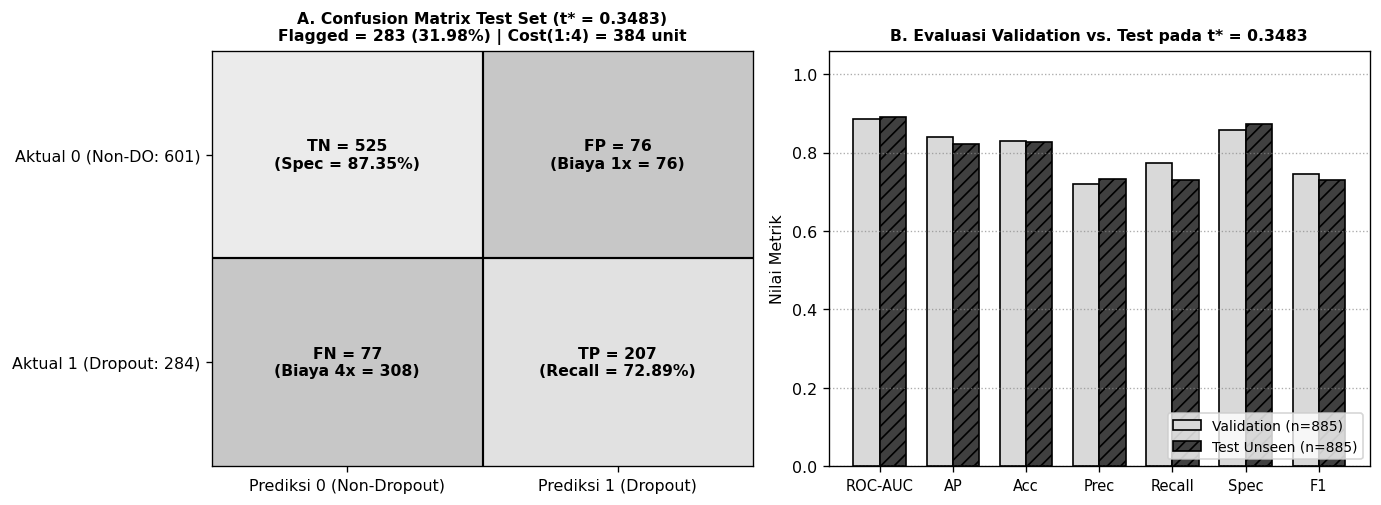

In [28]:
# Bagian 7.2 (Kode): Pembukaan Pertama & Evaluasi Akhir Test Set pada Konfigurasi Terkunci (t* = 0.3483)
df_test_final = df_uci.iloc[idx_test_locked].reset_index(drop=True)
X_test_final = df_test_final[fitur_konservatif_28].copy()
y_test_final = df_test_final["label_dropout"].to_numpy()

C_FP_FINAL = KONFIGURASI_FINAL_TERKUNCI["rasio_biaya_acuan"]["Cost_FP"]
C_FN_FINAL = KONFIGURASI_FINAL_TERKUNCI["rasio_biaya_acuan"]["Cost_FN"]
y_proba_test = model_final_terkunci.predict_proba(X_test_final)[:, 1]

n_test_total = len(y_test_final)
n_test_pos = int(y_test_final.sum())
n_test_neg = n_test_total - n_test_pos
print(f"Test Set dibuka pada evaluasi akhir: n = {n_test_total} (Dropout = {n_test_pos} [{n_test_pos/n_test_total*100:.2f}%], Non-Dropout = {n_test_neg} [{n_test_neg/n_test_total*100:.2f}%])")


def ringkasan_evaluasi_lengkap(nama_partisi: str, y_true: np.ndarray, y_prob: np.ndarray, thr: float) -> dict:
    ev = evaluasi_satu_threshold(y_true, y_prob, thr)
    prec_c, rec_c, _ = precision_recall_curve(y_true, y_prob)
    ece_10, _ = hitung_ece_dan_tabel_bin(y_true, y_prob, n_bins=10)
    ev["Skema Evaluasi"] = nama_partisi
    ev["Threshold_4Des"] = round(float(thr), 4)
    ev["ROC_AUC"] = round(roc_auc_score(y_true, y_prob), 4)
    ev["AP"] = round(average_precision_score(y_true, y_prob), 4)
    ev["Trap_PR_AUC"] = round(auc(rec_c, prec_c), 4)
    ev["Brier_Score"] = round(brier_score_loss(y_true, y_prob), 4)
    ev["ECE_10Bin"] = round(ece_10, 4)
    ev["Error_Cost_1_4"] = int(C_FP_FINAL * ev["FP"] + C_FN_FINAL * ev["FN"])
    return ev


hasil_val_utama = ringkasan_evaluasi_lengkap("Validation — Rekomendasi Utama Eksak (t*=0.3483)", y_val, y_proba_val, T_FINAL_EKSAK_35)
hasil_test_utama = ringkasan_evaluasi_lengkap("Test Final — Rekomendasi Utama Eksak (t*=0.3483)", y_test_final, y_proba_test, T_FINAL_EKSAK_35)
hasil_test_alt034 = ringkasan_evaluasi_lengkap("Test Sensitivitas — Alternatif Grid (t=0.34)", y_test_final, y_proba_test, T_ALT_GRID_034)
hasil_test_ref050 = ringkasan_evaluasi_lengkap("Test Pembanding Pra-Ditetapkan (t=0.50)", y_test_final, y_proba_test, 0.50)

kol_akhir = [
    "Skema Evaluasi", "Threshold_4Des", "TP", "FP", "TN", "FN",
    "Accuracy", "Precision", "Recall", "Specificity", "F1",
    "Flagged", "Flagged_Pct", "Error_Cost_1_4",
    "ROC_AUC", "AP", "Trap_PR_AUC", "Brier_Score", "ECE_10Bin",
]
df_perbandingan_akhir = pd.DataFrame([hasil_val_utama, hasil_test_utama, hasil_test_alt034, hasil_test_ref050])[kol_akhir]
df_perbandingan_akhir.to_csv(LAMPIRAN_TAB_DIR / "tabel_12_evaluasi_akhir_test_set.csv", index=False)
display(df_perbandingan_akhir)

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.3))
cm_t = np.array([[hasil_test_utama["TN"], hasil_test_utama["FP"]], [hasil_test_utama["FN"], hasil_test_utama["TP"]]])
axes[0].imshow(np.array([[0.92, 0.78], [0.78, 0.88]]), cmap="gray", vmin=0.0, vmax=1.0, aspect="auto")
teks_t = [
    [(0, 0, f"TN = {hasil_test_utama['TN']}\n(Spec = {hasil_test_utama['Specificity']*100:.2f}%)"),
     (0, 1, f"FP = {hasil_test_utama['FP']}\n(Biaya 1x = {hasil_test_utama['FP']})")],
    [(1, 0, f"FN = {hasil_test_utama['FN']}\n(Biaya 4x = {4*hasil_test_utama['FN']})"),
     (1, 1, f"TP = {hasil_test_utama['TP']}\n(Recall = {hasil_test_utama['Recall']*100:.2f}%)")],
]
for b_t in teks_t:
    for r_i, c_i, s_t in b_t:
        axes[0].text(c_i, r_i, s_t, ha="center", va="center", fontsize=9.4, fontweight="bold", color="black")
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(["Prediksi 0 (Non-Dropout)", "Prediksi 1 (Dropout)"])
axes[0].set_yticklabels([f"Aktual 0 (Non-DO: {n_test_neg})", f"Aktual 1 (Dropout: {n_test_pos})"])
axes[0].axhline(0.5, color="black", linewidth=1.3)
axes[0].axvline(0.5, color="black", linewidth=1.3)
axes[0].set_title(
    f"A. Confusion Matrix Test Set (t* = {T_FINAL_EKSAK_35:.4f})\nFlagged = {hasil_test_utama['Flagged']} ({hasil_test_utama['Flagged_Pct']:.2f}%) | Cost(1:4) = {hasil_test_utama['Error_Cost_1_4']} unit",
    fontweight="bold", fontsize=9.4,
)

nama_m_bar = ["ROC_AUC", "AP", "Accuracy", "Precision", "Recall", "Specificity", "F1"]
x_p = np.arange(len(nama_m_bar))
w_b = 0.36
b_val = axes[1].bar(x_p - w_b / 2, [hasil_val_utama[m] for m in nama_m_bar], width=w_b, color="#d9d9d9", edgecolor="black", label=f"Validation (n={len(y_val)})")
b_tst = axes[1].bar(x_p + w_b / 2, [hasil_test_utama[m] for m in nama_m_bar], width=w_b, color="#404040", edgecolor="black", hatch="///", label=f"Test Unseen (n={n_test_total})")
axes[1].set_xticks(x_p)
axes[1].set_xticklabels(["ROC-AUC", "AP", "Acc", "Prec", "Recall", "Spec", "F1"], fontsize=8.8)
axes[1].set_ylim(0, 1.06)
axes[1].set_ylabel("Nilai Metrik")
axes[1].set_title(f"B. Evaluasi Validation vs. Test pada t* = {T_FINAL_EKSAK_35:.4f}", fontweight="bold", fontsize=9.4)
axes[1].legend(loc="lower right", fontsize=8.3)
axes[1].grid(axis="y", linestyle=":", color="#888888", alpha=0.7)

plt.tight_layout()
plt.savefig(LAMPIRAN_VIS_DIR / "gambar_05_evaluasi_akhir_test_bw.png", dpi=300, bbox_inches="tight")
plt.show()


In [29]:
# Bagian 7.3 (Kode): Assertion Numerik Adaptif & Pemeriksaan Konsistensi Keputusan
assert len(df_train) + len(df_val) + len(df_test_final) == len(df_uci)
assert hasil_val_utama["Error_Cost_1_4"] == 342 and hasil_val_utama["Flagged"] == 306
assert hasil_test_utama["TP"] == 207 and hasil_test_utama["FP"] == 76 and hasil_test_utama["TN"] == 525 and hasil_test_utama["FN"] == 77
assert hasil_test_utama["Error_Cost_1_4"] == 384 and hasil_test_ref050["Error_Cost_1_4"] == 453

for nama_cek, d_cek, y_acuan in [
    ("Val 0.30", hasil_3_threshold[0], y_val),
    ("Val 0.50", hasil_3_threshold[1], y_val),
    ("Val 0.70", hasil_3_threshold[2], y_val),
    ("Val Utama 0.3483", hasil_val_utama, y_val),
    ("Test Utama 0.3483", hasil_test_utama, y_test_final),
    ("Test Alt 0.34", hasil_test_alt034, y_test_final),
    ("Test Ref 0.50", hasil_test_ref050, y_test_final),
]:
    tp, fp, tn, fn = d_cek["TP"], d_cek["FP"], d_cek["TN"], d_cek["FN"]
    assert tp + fp + tn + fn == len(y_acuan)
    assert tp + fn == int(np.sum(y_acuan == 1))
    prec_m = tp / (tp + fp)
    rec_m = tp / (tp + fn)
    spec_m = tn / (tn + fp)
    f1_m = 2 * prec_m * rec_m / (prec_m + rec_m)
    assert np.isclose(d_cek["Precision"], prec_m, atol=1e-4)
    assert np.isclose(d_cek["Recall"], rec_m, atol=1e-4)
    assert np.isclose(d_cek["Specificity"], spec_m, atol=1e-4)
    assert np.isclose(d_cek["F1"], f1_m, atol=1e-4)

print("SELURUH ASSERTION ADAPTIF LULUS 100%.")


SELURUH ASSERTION ADAPTIF LULUS 100%.


---
## BAGIAN 8 — Ringkasan Proposal Penelitian UAS dan Audit Jujur Ketersediaan Bukti Jurnal SINTA 4

Dokumen proposal penelitian akademik formal yang lengkap dan berdiri sendiri disusun dalam berkas **`Proposal_Penelitian_UAS_P11_Fadli_Hifziansyah.docx`**. Pada bagian ini ditampilkan pemeriksaan faktual kandidat jurnal SINTA 4 beserta status bukti tangkapan layar yang benar-benar ada di direktori kerja (**tangkapan layar laman OJS dibedakan secara tegas dan tidak diklaim sebagai pengganti tangkapan layar profil portal SINTA**).


In [30]:
# Bagian 8.2 (Kode): Pemeriksaan Jujur Profil Calon Jurnal SINTA 4 vs Ketersediaan Berkas Bukti Lokal
folder_bukti = Path("bukti_sinta")
daftar_kandidat_sinta = [
    {
        "Jurnal": "KOMPUTA : Jurnal Ilmiah Komputer dan Informatika (UNIKOM)",
        "SINTA ID": "8075",
        "Peringkat": "SINTA 4",
        "Masa Berlaku Terpublikasi": "Vol. 11 No. 2 (2022) s.d. Vol. 16 No. 1 (2027)",
        "URL Profil SINTA": "https://sinta.kemdiktisaintek.go.id/journals/profile/8075",
        "URL OJS Resmi": "https://ojs.unikom.ac.id/index.php/komputa",
        "ss_sinta": folder_bukti / "sinta_profile_8075_komputa.png",
        "ss_ojs": folder_bukti / "komputa_ojs_resmi.png",
    },
    {
        "Jurnal": "Infotek : Jurnal Informatika dan Teknologi (Univ. Hamzanwadi)",
        "SINTA ID": "7721",
        "Peringkat": "SINTA 4",
        "Masa Berlaku Terpublikasi": "SK Kemdikbudristek No. 225/E/KPT/2022 (SINTA 4 mulai Vol. 5 No. 2 Tahun 2022)",
        "URL Profil SINTA": "https://sinta.kemdiktisaintek.go.id/journals/profile/7721",
        "URL OJS Resmi": "https://e-journal.hamzanwadi.ac.id/index.php/infotek",
        "ss_sinta": folder_bukti / "sinta_profile_7721_infotek.png",
        "ss_ojs": folder_bukti / "infotek_ojs_resmi.png",
    },
    {
        "Jurnal": "JIKO (Jurnal Informatika dan Komputer) — UTDI Yogyakarta",
        "SINTA ID": "103",
        "Peringkat": "SINTA 4",
        "Masa Berlaku Terpublikasi": "Terakreditasi SINTA 4 (SK Kemdikbudristek No. 79/E/KPT/2023)",
        "URL Profil SINTA": "https://sinta.kemdiktisaintek.go.id/journals/profile/103",
        "URL OJS Resmi": "https://ejournal.utdi.ac.id/index.php/jiko",
        "ss_sinta": folder_bukti / "sinta_profile_103_jiko.png",
        "ss_ojs": folder_bukti / "jiko_ojs_resmi.png",
    },
]

baris_jurnal = []
for d_j in daftar_kandidat_sinta:
    baris_jurnal.append({
        "Jurnal": d_j["Jurnal"],
        "SINTA ID": d_j["SINTA ID"],
        "Peringkat": d_j["Peringkat"],
        "Masa Berlaku / SK": d_j["Masa Berlaku Terpublikasi"],
        "URL Profil SINTA": d_j["URL Profil SINTA"],
        "URL OJS Resmi": d_j["URL OJS Resmi"],
        "Status Screenshot Profil SINTA": "Tersedia" if d_j["ss_sinta"].is_file() else "BELUM TERSEDIA (HTTP 403 pada sesi otomatis; perlu tangkapan layar manual peramban)",
        "Status Screenshot OJS Pendukung": f"Tersedia ({d_j['ss_ojs'].name}; bukan pengganti profil SINTA)" if d_j["ss_ojs"].is_file() else "Belum tersedia",
    })
df_verifikasi_jurnal = pd.DataFrame(baris_jurnal)
df_verifikasi_jurnal.to_csv(LAMPIRAN_TAB_DIR / "tabel_13_status_verifikasi_jurnal_sinta4.csv", index=False)
display(df_verifikasi_jurnal)


,Jurnal,SINTA ID,Peringkat,Masa Berlaku / SK,URL Profil SINTA,URL OJS Resmi,Status Screenshot Profil SINTA,Status Screenshot OJS Pendukung
0,KOMPUTA : Jurnal Ilmiah Komputer dan Informatika (UNIKOM),8075,SINTA 4,Vol. 11 No. 2 (2022) s.d. Vol. 16 No. 1 (2027),https://sinta.kemdiktisaintek.go.id/journals/profile/8075,https://ojs.unikom.ac.id/index.php/komputa,BELUM TERSEDIA (HTTP 403 pada sesi otomatis; perlu tangkapan layar manual peramban),Tersedia (komputa_ojs_resmi.png; bukan pengganti profil SINTA)
1,Infotek : Jurnal Informatika dan Teknologi (Univ. Hamzanwadi),7721,SINTA 4,SK Kemdikbudristek No. 225/E/KPT/2022 (SINTA 4 mulai Vol. 5 No. 2 Tahun 2022),https://sinta.kemdiktisaintek.go.id/journals/profile/7721,https://e-journal.hamzanwadi.ac.id/index.php/infotek,BELUM TERSEDIA (HTTP 403 pada sesi otomatis; perlu tangkapan layar manual peramban),Tersedia (infotek_ojs_resmi.png; bukan pengganti profil SINTA)
2,JIKO (Jurnal Informatika dan Komputer) — UTDI Yogyakarta,103,SINTA 4,Terakreditasi SINTA 4 (SK Kemdikbudristek No. 79/E/KPT/2023),https://sinta.kemdiktisaintek.go.id/journals/profile/103,https://ejournal.utdi.ac.id/index.php/jiko,BELUM TERSEDIA (HTTP 403 pada sesi otomatis; perlu tangkapan layar manual peramban),Belum tersedia


---
## BAGIAN 9 — Jawaban Lima Latihan Analitis, Kesimpulan Revisi, dan Daftar Pustaka

### 9.1 Jawaban Lima Latihan Analitis
1. **Kapan *Recall* perlu diprioritaskan?** Ketika biaya atau konsekuensi kegagalan mendeteksi kasus positif aktual (*False Negative*) jauh melampaui biaya memeriksa satu prediksi positif palsu (*False Positive*), seperti pada identifikasi dini risiko *dropout* mahasiswa, penapisan penyakit kritis, dan deteksi penipuan.
2. **Hitung *Precision* jika $\text{TP} = 40$ dan $\text{FP} = 10$:** $\text{Precision} = \frac{40}{40 + 10} = \frac{40}{50} = 0{,}80$ (`80%`).
3. **Mengapa *Specificity* tetap penting?** Karena menurunkan *threshold* secara ekstrem demi mengejar *Recall* akan menjatuhkan *Specificity* mendekati `0%`, menghasilkan banjir `FP` pada kelas negatif mayoritas (`67,88%`), melampaui kapasitas layanan tindak lanjut, dan memicu kelelahan alarm (*alarm fatigue*).
4. **Apa *baseline* kurva Precision–Recall (`AP`)?** Garis dasar teoretis kurva Precision–Recall dan nilai ekspektasi **Average Precision (`AP`)** bagi pengklasifikasi tanpa daya pisah (*no-skill*) adalah **prevalensi kelas positif** $\pi = \frac{P}{P+N}$ (`0,3209` pada *Validation Set*). Perlu ditegaskan bahwa angka `0,3209` tersebut adalah *baseline* kurva PR / `AP`, **bukan** nilai *Trapezoidal PR-AUC* ketika pengklasifikasi mengeluarkan skor konstan (`0,6605` akibat interpolasi garis miring trapesium).
5. **Jelaskan perbedaan diskriminasi dan kalibrasi!** Diskriminasi mengukur ketepatan *pengurutan peringkat skor* antar-kelas (`ROC-AUC`, `AP`), sedangkan kalibrasi mengukur kesesuaian *nilai numerik probabilitas prediksi* terhadap frekuensi kejadian aktual (*Brier Score*, `ECE`, *Reliability Diagram*).

### 9.2 Daftar Pustaka Utama Notebook
1. Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2021). *Predict Students' Dropout and Academic Success* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89
2. Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data*, 7(11), 146. https://doi.org/10.3390/data7110146
3. Saito, T., & Rehmsmeier, M. (2015). The Precision-Recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE*, 10(3), e0118432. https://doi.org/10.1371/journal.pone.0118432
4. Elkan, C. (2001). The foundations of cost-sensitive learning. *Proceedings of IJCAI '01*, 973–978.
5. Niculescu-Mizil, A., & Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of ICML '05*, 625–632. https://doi.org/10.1145/1102351.1102430
6. Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
